# Indego Bike Share: Unsupervised

Subject to change with real data. Was more interested in the steps.

In [1]:
import sys

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    import importlib
    import subprocess

    for package, module in (
        ("pandas", "pandas"),
        ("pyarrow", "pyarrow"),
        ("numpy", "numpy"),
        ("matplotlib", "matplotlib"),
        ("scipy", "scipy"),
        ("scikit-learn", "sklearn"),
        ("jinja2", "jinja2"),
    ):
        try:
            importlib.import_module(module)
        except ImportError:
            subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", package])
    from google.colab import drive

    drive.mount("/content/drive")
    print("Colab runtime. Drive mounted at /content/drive.")
    print("Reading MyDrive/Milestone II/data/processed/.")
else:
    print("Local runtime.")

Mounted at /content/drive
Colab runtime. Drive mounted at /content/drive.
Reading MyDrive/Milestone II/data/processed/.


In [47]:
# Setup: Libraries
import json
import os
import warnings
from dataclasses import dataclass, field
from pathlib import Path
from typing import Callable

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from scipy.cluster.hierarchy import dendrogram, fcluster, linkage, set_link_color_palette
from scipy.optimize import linear_sum_assignment
from sklearn.cluster import DBSCAN, AgglomerativeClustering, KMeans
from sklearn.decomposition import NMF, PCA
from sklearn.exceptions import ConvergenceWarning
from sklearn.manifold import TSNE
from sklearn.metrics import adjusted_rand_score, silhouette_samples, silhouette_score
from sklearn.mixture import GaussianMixture
# from sklearn.model_selection import train_test_split
from sklearn.model_selection import cross_val_score, train_test_split
from sklearn.neighbors import NearestNeighbors, kneighbors_graph
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier, export_text

# Defining custom colors and plot formatting used by the visualizations in this notebook
BLUE = "#1f77b4"
MUTED = "#7f7f7f"
INK = "#0f0f0f"

def suptitle(fig, text):
    fig.suptitle(text, color=INK, fontsize=12, weight="bold")

## Load Data

The trips (all quarterly files) and the station list. Parsed trips are at `data/cache/trips.parquet` (replace with actual folders in shared drive) .

[↑ Contents](#contents)

In [48]:
ROOT = Path("/content/drive/MyDrive/Milestone II") if IN_COLAB else Path.cwd().resolve()
PROCESSED = ROOT / "data/processed"
SHARED = ROOT / "data/shared"
EXPORTS = ROOT / "results/unsupervised/forecast_export"

settings_path = ROOT / "project_settings.json"
if not settings_path.is_file():
    raise FileNotFoundError(f"Missing {settings_path}. Run notebook 01 first.")
settings = json.loads(settings_path.read_text())
STUDY_START = pd.Timestamp(settings["study_start"])
TRAIN_END = pd.Timestamp(settings["train_end"])
VAL_END = pd.Timestamp(settings["validation_end"])
TEST_END = pd.Timestamp(settings["test_end"])
PROFILE_AVAILABLE_FROM = pd.Timestamp(settings["forecast_profiles_available_from"])
CV_WINDOWS = settings["forward_validation_windows"]
assert STUDY_START < PROFILE_AVAILABLE_FROM < TRAIN_END < VAL_END < TEST_END
assert all(PROFILE_AVAILABLE_FROM < pd.Timestamp(a) < pd.Timestamp(b) <= VAL_END
           for a, b in CV_WINDOWS)
if settings["timezone"] != "America/New_York":
    raise ValueError("The processed timestamps must use Philadelphia local time.")

import hashlib

def file_hash(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()

shared_path = SHARED / "shared_manifest.json"
if not shared_path.is_file():
    raise FileNotFoundError("Run 02_shared_analysis_prep.ipynb for these processed files first.")
contract = json.loads(shared_path.read_text())
if contract["settings"] != settings:
    raise ValueError("Settings changed. Rerun 02 before 04.")
for name, expected in contract["sources"].items():
    if file_hash(PROCESSED / name) != expected:
        raise ValueError(f"{name} changed. Rerun 02 before 04.")
print("Project:", ROOT)
print("Shared source and date checks passed.")

Project: /content/drive/MyDrive/Milestone II
Shared source and date checks passed.


In [49]:
def load_trips() -> pd.DataFrame:
    frame = pd.read_parquet(PROCESSED / "trips_clean.parquet").rename(columns={
        "start_station_id": "start_station", "end_station_id": "end_station",
        "duration_min": "duration",
    })
    required = ["trip_id", "start_time", "end_time", "start_station", "end_station", "duration",
                "start_lat", "start_lon", "end_lat", "end_lon", "distance_km",
                "trip_route_category", "passholder_type", "bike_type"]
    missing = sorted(set(required) - set(frame.columns))
    if missing:
        raise ValueError(f"Processed trip columns missing: {missing}. Rerun 01.")
    for column in ["start_time", "end_time"]:
        frame[column] = pd.to_datetime(frame[column])
        if frame[column].dt.tz is not None:
            raise ValueError("Expected local, timezone-naive timestamps from 01.")
    frame = frame.loc[frame.start_time.ge(STUDY_START) & frame.start_time.lt(TEST_END)].copy()
    frame["quarter"] = frame.start_time.dt.to_period("Q").astype(str).str.lower().str.replace("q", "-q", regex=False)
    return frame


def load_stations() -> pd.DataFrame:
    frame = pd.read_parquet(PROCESSED / "stations.parquet").rename(columns={
        "station_id": "Station_ID", "station_name": "Station_Name",
    })
    if not {"Station_ID", "Station_Name"}.issubset(frame.columns):
        raise ValueError("Processed stations must contain station_id and station_name. Rerun 01.")
    assert frame.Station_ID.is_unique
    return frame

In [50]:
trips = load_trips()
stations = load_stations()


def quarter_labels(start, end):
    periods = pd.period_range(start, end - pd.Timedelta(nanoseconds=1), freq="Q")
    return [f"{p.year}-q{p.quarter}" for p in periods]


TRAIN_QUARTERS = quarter_labels(STUDY_START, TRAIN_END)
VALIDATION_QUARTERS = quarter_labels(TRAIN_END, VAL_END)
TEST_QUARTERS = quarter_labels(VAL_END, TEST_END)
assert set(TRAIN_QUARTERS + VALIDATION_QUARTERS + TEST_QUARTERS) == set(trips["quarter"]), "a study quarter is missing or unexpected"

print(f"Trips: {len(trips):,} rows across {trips['quarter'].nunique()} quarters")
print(f"Training: {TRAIN_QUARTERS[0]} to {TRAIN_QUARTERS[-1]} ({len(TRAIN_QUARTERS)} quarters)")
print(f"Validation: {', '.join(VALIDATION_QUARTERS)} | Test: {', '.join(TEST_QUARTERS)}")
print(f"Stations: {len(stations):,}")
print(f"Date range: {trips['start_time'].min()} to {trips['start_time'].max()}")
print(f"Duplicate trip IDs and start times: {trips.duplicated(['trip_id', 'start_time']).sum():,}")

Trips: 3,316,664 rows across 10 quarters
Training: 2024-q1 to 2025-q4 (8 quarters)
Validation: 2026-q1 | Test: 2026-q2
Stations: 385
Date range: 2024-01-01 00:04:00 to 2026-06-30 23:58:00
Duplicate trip IDs and start times: 0


## Helpers

In [51]:
for name in ["trips_clean.parquet", "stations.parquet"]:
    print(PROCESSED / name)

/content/drive/MyDrive/Milestone II/data/processed/trips_clean.parquet
/content/drive/MyDrive/Milestone II/data/processed/stations.parquet


In [52]:
# Shared helpers: trip features and the station table
# Cleaning rules
VIRTUAL_STATION = 3000  # has no coordinates
REDOCK_MAX_MIN = 2      # round trips this short are immediate re-docks, not rides
MAX_DURATION_MIN = 240  # longer trips are mostly bikes kept overnight or hitting the 24 h cap

TRIP_FEATURES = ["log_duration", "log_dist", "speed_kmh", "round_trip", "hour_sin", "hour_cos", "weekend"]
EARTH_RADIUS_KM = 6371
PHILLY_LAT = 39.95


def planar_km(lat, lon):
    """Local planar coordinates in km around Philadelphia (good to <1% across the service area)."""
    return np.column_stack([np.asarray(lon) * 111.32 * np.cos(np.radians(PHILLY_LAT)), np.asarray(lat) * 110.57])


def prepare_trips(trips: pd.DataFrame) -> pd.DataFrame:
    """Drop trips that aren't real rides, then add the behavioural clustering features (TRIP_FEATURES) plus helper
    and validation columns. Pass type and bike type are not clustering features; `casual` and `electric` are kept
    only to validate the clusters afterwards."""
    # 01 keeps valid departures even when arrival details are missing.
    # Clustering needs both endpoints, valid elapsed time, and finite coordinates.
    required = ["start_station", "end_station", "start_time", "end_time", "duration",
                "start_lat", "start_lon", "end_lat", "end_lon", "distance_km", "trip_route_category"]
    trips = trips.dropna(subset=required).copy()
    numeric = ["duration", "start_lat", "start_lon", "end_lat", "end_lon", "distance_km"]
    valid = np.isfinite(trips[numeric].to_numpy(dtype=float)).all(axis=1)
    valid &= trips["duration"].gt(0) & trips["end_time"].ge(trips["start_time"])
    trips = trips.loc[valid].copy()
    is_round = trips["trip_route_category"] == "Round Trip"
    keep = ((trips["start_station"] != VIRTUAL_STATION) & (trips["end_station"] != VIRTUAL_STATION)
            & ~(is_round & (trips["duration"] <= REDOCK_MAX_MIN)) & (trips["duration"] <= MAX_DURATION_MIN))
    df = trips[keep].copy()

    # straight-line (great-circle) distance between the two stations
    lat1, lon1, lat2, lon2 = (np.radians(df[c]) for c in ["start_lat", "start_lon", "end_lat", "end_lon"])
    a = np.sin((lat2 - lat1) / 2) ** 2 + np.cos(lat1) * np.cos(lat2) * np.sin((lon2 - lon1) / 2) ** 2
    df["dist_km"] = EARTH_RADIUS_KM * 2 * np.arcsin(np.sqrt(a))
    # straight-line speed; 1-minute trips give absurd values, so cap at 30 km/h
    df["speed_kmh"] = (df["dist_km"] / (df["duration"] / 60)).clip(upper=30)
    df["round_trip"] = is_round[keep].astype(int)
    df["hour"] = df["start_time"].dt.hour
    df["end_hour"] = df["end_time"].dt.hour
    # time of day as a point on a circle, so 23:00 and 00:00 are neighbours
    frac_hour = df["hour"] + df["start_time"].dt.minute / 60
    df["hour_sin"] = np.sin(2 * np.pi * frac_hour / 24)
    df["hour_cos"] = np.cos(2 * np.pi * frac_hour / 24)
    df["weekend"] = (df["start_time"].dt.dayofweek >= 5).astype(int)
    df["am_peak"] = ((df["weekend"] == 0) & df["hour"].between(6, 9)).astype(int)
    df["log_duration"] = np.log(df["duration"])
    df["log_dist"] = np.log1p(df["dist_km"])
    df["casual"] = df["passholder_type"].isin(["Day Pass", "Walk-up"]).astype(int)
    df["electric"] = (df["bike_type"] == "electric").astype(int)
    return df


def trip_ends(trips: pd.DataFrame, extra: tuple[str, ...] = ()) -> pd.DataFrame:
    """One row per trip end: a departure (flow −1, start hour) at the start station and an arrival
    (flow +1, end hour) at the end station. `weekend` follows the trip's start time for both ends."""
    cols = ["weekend", *extra]
    departures = trips[["start_station", "hour", *cols]].rename(columns={"start_station": "station"}).assign(flow=-1)
    arrivals = (trips[["end_station", "end_hour", *cols]]
                .rename(columns={"end_station": "station", "end_hour": "hour"}).assign(flow=1))
    return pd.concat([departures, arrivals], ignore_index=True)


def peak_net_flow(ends: pd.DataFrame, first_hour: int, last_hour: int) -> pd.Series:
    """Per station: (arrivals − departures) / (arrivals + departures) on weekdays, hours first..last inclusive.

    +1 means every bike movement in the window was an arrival, −1 every one a departure.
    """
    window = ends[(ends["weekend"] == 0) & ends["hour"].between(first_hour, last_hour)].groupby("station")["flow"]
    return window.sum() / window.size()


def station_table(ends: pd.DataFrame, trips: pd.DataFrame, stations: pd.DataFrame, min_ends: int) -> pd.DataFrame:
    """One row per station: share of its trip ends in each purpose, weekday AM (06–09) and PM (15–18) net flow,
    trip-end count, casual share, location and name. Stations with fewer than `min_ends` trip ends are dropped."""
    table = (pd.crosstab(ends["station"], ends["purpose"], normalize="index")
             .assign(am_net=peak_net_flow(ends, 6, 9), pm_net=peak_net_flow(ends, 15, 18),
                     trip_ends=ends.groupby("station").size(), casual=ends.groupby("station")["casual"].mean())
             .fillna({"am_net": 0, "pm_net": 0}))
    table.columns.name = None
    location = trips.groupby("start_station")[["start_lat", "start_lon"]].median()
    table = table.join(location.rename(columns={"start_lat": "lat", "start_lon": "lon"}))
    table = table.join(stations.set_index("Station_ID")["Station_Name"])
    return table[table["trip_ends"] >= min_ends].copy()


def temporal_profile(trips: pd.DataFrame, station_ids: pd.Index) -> pd.DataFrame:
    """Per station: share of its trip ends that are departures / arrivals in each hour, weekday and weekend.

    96 columns (direction × weekend × hour) that sum to 1 per station.
    """
    dep = trips.groupby(["start_station", "weekend", "hour"]).size().rename_axis(["station", "weekend", "hour"])
    arr = trips.groupby(["end_station", "weekend", "end_hour"]).size().rename_axis(["station", "weekend", "hour"])
    profile = (pd.concat({"dep": dep, "arr": arr}, names=["dir"])
               .unstack(["dir", "weekend", "hour"], fill_value=0)
               .reindex(index=station_ids, fill_value=0)
               .reindex(columns=pd.MultiIndex.from_product([["dep", "arr"], [0, 1], range(24)]), fill_value=0))
    return profile.div(profile.sum(axis=1), axis=0)

In [86]:
# Shared helpers: clustering, assignment to frozen clusters, stability, mixtures
def kmeans_vs_ward(X, ks, n_init: int = 50) -> pd.DataFrame:
    """For each k: k-means silhouette, and agreement (ARI) between k-means and Ward hierarchical clustering."""
    rows = []
    for k in ks:
        kmeans_labels = KMeans(k, n_init=n_init, random_state=0).fit_predict(X)
        ward_labels = AgglomerativeClustering(k).fit_predict(X)
        rows.append({"k": k,
                     "silhouette": silhouette_score(X, kmeans_labels),
                     "ARI vs Ward": adjusted_rand_score(kmeans_labels, ward_labels),
                     "cluster sizes": sorted(np.bincount(kmeans_labels).tolist(), reverse=True)})
    return pd.DataFrame(rows).set_index("k")


def name_by_rules(profile: pd.DataFrame, rules: list[tuple]) -> dict:
    """Name clusters from their profile, so names survive k-means label permutation.

    `rules` is an ordered list of (name, column, "max" | "min"). Each rule picks, among clusters not yet
    named, the one with the highest / lowest value in `column`. A final (name, None, None) names the one
    cluster left over.
    """
    remaining, names = list(profile.index), {}
    for name, column, pick in rules:
        if column is None:
            if len(remaining) != 1:
                raise ValueError(f"'{name}' should be the last cluster left, but {len(remaining)} remain")
            chosen = remaining[0]
        else:
            values = profile.loc[remaining, column]
            chosen = values.idxmax() if pick == "max" else values.idxmin()
        names[chosen] = name
        remaining.remove(chosen)
    if remaining:
        raise ValueError(f"Clusters left unnamed: {remaining}")
    return names


def nearest_centroids(X_scaled, centroids):
    """Nearest and second-nearest centroid for each row, plus a boundary margin.

    margin = (d2 − d1) / (d2 + d1): 0 means equidistant from two centroids (on the boundary), 1 means at a centroid.
    Returns (nearest, runner_up, margin) as arrays.
    """
    distances = np.linalg.norm(np.asarray(X_scaled)[:, None, :] - centroids[None], axis=2)
    order = np.argsort(distances, axis=1)
    d1 = np.take_along_axis(distances, order[:, :1], axis=1)[:, 0]
    d2 = np.take_along_axis(distances, order[:, 1:2], axis=1)[:, 0]
    return order[:, 0], order[:, 1], (d2 - d1) / (d2 + d1)


def bootstrap_confidence(counts, labels, scaler, centroids, n_boot: int = 200, seed: int = 0,
                         size: int | None = None) -> np.ndarray:
    """Share of bootstrap resamples that keep each row in its assigned cluster.

    Each row of `counts` is a station's trip-end counts per purpose. It is resampled `n_boot` times as a multinomial
    (with the station's own total, or `size` trip ends if given, to ask "how stable would this type be with n trips?"),
    converted back to shares, scaled with the frozen `scaler`, and reassigned to the nearest centroid.
    """
    counts = np.asarray(counts)
    rng = np.random.default_rng(seed)
    resampled_shares = []
    for row in counts:  # one row at a time, in order, so the random draws are reproducible
        total = row.sum() if size is None else size
        resampled_shares.append(rng.multinomial(total, row / row.sum(), size=n_boot) / total)
    stacked = pd.DataFrame(np.vstack(resampled_shares), columns=getattr(scaler, "feature_names_in_", None))
    assigned = nearest_centroids(scaler.transform(stacked), centroids)[0].reshape(len(counts), n_boot)
    return (assigned == np.asarray(labels)[:, None]).mean(axis=1)


def k_distance(X, k: int) -> np.ndarray:
    """Sorted distance from each point to its k-th neighbour (the point itself counts as the first)."""
    return np.sort(NearestNeighbors(n_neighbors=k).fit(X).kneighbors(X)[0][:, -1])


def resample_stability(X, k: int, reference, sizes, reps: int = 3, n_init: int = 10, replace: bool = False,
                       seed: int = 0) -> pd.DataFrame:
    """Fit k-means on random subsamples (or bootstrap samples with replace=True) of each size, label every row of X
    with the fitted model, and measure agreement (ARI) with the `reference` labels."""
    X = np.asarray(X)
    rng = np.random.default_rng(seed)
    rows = []
    for size in sizes:
        for rep in range(reps):
            sample = rng.choice(len(X), size, replace=replace)
            model = KMeans(k, n_init=n_init, random_state=rep).fit(X[sample])
            rows.append({"size": size, "rep": rep, "ARI vs reference": adjusted_rand_score(reference, model.predict(X))})
    return pd.DataFrame(rows)

GMM_REG_COVAR = 1e-3  # keeps covariances invertible when a cluster is constant in a 0/1 feature (round trip, weekend)


def fit_gmm(X, k: int, covariance_type: str = "full", n_init: int = 2, seed: int = 0) -> GaussianMixture:
    return GaussianMixture(k, covariance_type=covariance_type, reg_covar=GMM_REG_COVAR, n_init=n_init,
                           random_state=seed).fit(X)


def fit_nmf_mixtures(V: pd.DataFrame, rank: int, seed: int = 0) -> tuple[pd.DataFrame, pd.DataFrame]:
    """Factor V (rows = items, non-negative) as W·H with `rank` signatures.

    Returns (mixtures, signatures). Each signature (row of H) is rescaled to sum to 1, so it reads as a profile, and
    each item's weights are rescaled to sum to 1, so they read as "x% of this signature".
    """
    model = NMF(rank, init="nndsvda", max_iter=2000, random_state=seed)
    W = model.fit_transform(V.to_numpy())
    H = model.components_
    scale = H.sum(axis=1)
    H, W = H / scale[:, None], W * scale[None, :]
    names = [f"S{i + 1}" for i in range(rank)]
    mixtures = pd.DataFrame(W / W.sum(axis=1, keepdims=True), index=V.index, columns=names)
    signatures = pd.DataFrame(H, index=names, columns=V.columns)
    return mixtures, signatures


def describe_partition(labels, X, reference, metric: str = "euclidean") -> dict:
    """Clusters, noise share, silhouette and ARI vs a reference partition. Noise (label −1) is excluded from
    silhouette and ARI. With metric="precomputed", X is a square distance matrix."""
    labels = np.asarray(labels)
    core = labels >= 0
    n_clusters = len(set(labels[core]))
    X_core = np.asarray(X)[np.ix_(core, core)] if metric == "precomputed" else np.asarray(X)[core]
    if n_clusters < 2:
        return {"clusters": n_clusters, "noise": 1 - core.mean(), "silhouette": np.nan, "ARI vs k-means": np.nan}
    return {"clusters": n_clusters,
            "noise": 1 - core.mean(),
            "silhouette": silhouette_score(X_core, labels[core], metric=metric),
            "ARI vs k-means": adjusted_rand_score(np.asarray(reference)[core], labels[core])}


def co_membership(test_labels, predicted_labels) -> float:
    """Prediction strength of one split: for each test cluster, the share of its point pairs that the training
    model also puts together; the weakest cluster sets the score."""
    shares = []
    for cluster in np.unique(test_labels):
        counts = np.bincount(predicted_labels[test_labels == cluster])
        n = counts.sum()
        if n > 1:
            shares.append((counts * (counts - 1)).sum() / (n * (n - 1)))
    return min(shares)


def prediction_strength(X, ks, n_splits: int = 10, n_init: int = 4, seed: int = 0) -> pd.DataFrame:
    """Tibshirani & Walther's prediction strength: split the rows in half, cluster each half, and check whether the
    training half's model groups the test half the way the test half's own clustering does. Values above ~0.8
    indicate clusters that replicate; it falls off once k exceeds the number of real, separable groups."""
    X = np.asarray(X)
    rng = np.random.default_rng(seed)
    halves = [np.array_split(rng.permutation(len(X)), 2) for _ in range(n_splits)]
    rows = []
    for split, (train_rows, test_rows) in enumerate(halves):
        for k in ks:
            train_model = KMeans(k, n_init=n_init, random_state=split).fit(X[train_rows])
            test_labels = KMeans(k, n_init=n_init, random_state=split).fit_predict(X[test_rows])
            rows.append({"k": k, "split": split,
                         "prediction strength": co_membership(test_labels, train_model.predict(X[test_rows]))})
    return pd.DataFrame(rows)


def gmm_sweep(X, ks, covariance_type: str = "full", n_init: int = 2, seed: int = 0) -> pd.DataFrame:
    """BIC and AIC of a Gaussian mixture at each k (lower is better; BIC penalises extra components harder)."""
    X = np.asarray(X)
    rows = []
    for k in ks:
        model = fit_gmm(X, k, covariance_type, n_init, seed)
        rows.append({"k": k, "BIC": model.bic(X), "AIC": model.aic(X)})
    return pd.DataFrame(rows).set_index("k")


def membership_summary(probabilities: np.ndarray) -> pd.DataFrame:
    """Per row: probability of the most likely component, and normalised entropy (0 = certain, 1 = evenly split)."""
    p = np.clip(np.asarray(probabilities), 1e-12, 1)
    entropy = -(p * np.log(p)).sum(axis=1) / np.log(p.shape[1])
    return pd.DataFrame({"max probability": p.max(axis=1), "entropy": entropy})


def drift_vs_frozen(X, frozen_model, n_init: int = 4, seed: int = 0) -> dict:
    """Refit k-means (same k) on new data X and compare it with a frozen model.

    Returns the agreement of their labels (ARI), the mean distance between matched centroids (Hungarian matching),
    and the mean distance of points to their frozen centroid (how well the old centres still describe the new data).
    """
    X = np.asarray(X)
    refit = KMeans(frozen_model.n_clusters, n_init=n_init, random_state=seed).fit(X)
    frozen_labels = frozen_model.predict(X)
    centroid_distances = np.linalg.norm(refit.cluster_centers_[:, None] - frozen_model.cluster_centers_[None], axis=2)
    matched_rows, matched_cols = linear_sum_assignment(centroid_distances)
    distance_to_frozen = np.linalg.norm(X - frozen_model.cluster_centers_[frozen_labels], axis=1)
    return {"ARI refit vs frozen": adjusted_rand_score(frozen_labels, refit.labels_),
            "centroid shift": centroid_distances[matched_rows, matched_cols].mean(),
            "mean distance to frozen centroid": distance_to_frozen.mean()}

# Model scorecard (used by the k-means vs GMM vs DBSCAN comparison)
@dataclass(frozen=True)
class Candidate:
    name: str
    fit: Callable[[np.ndarray], np.ndarray]  # row indices -> labels for those rows (−1 = noise)
    space: np.ndarray                        # features (or a square distance matrix) used for silhouette
    metric: str = "euclidean"                # "precomputed" when `space` is a distance matrix
    inputs: frozenset = field(default_factory=frozenset)  # held-out variables this candidate actually uses

def epsilon_squared(values, labels) -> float:
    """η² adjusted for the number of clusters: (SS_between − (k − 1)·MS_within) / SS_total. Near 0 for unrelated values."""
    values, labels = np.asarray(values, float), np.asarray(labels)
    clusters = np.unique(labels)
    grand_mean = values.mean()
    total = ((values - grand_mean) ** 2).sum()
    if total == 0:
        return np.nan
    between = sum((labels == c).sum() * (values[labels == c].mean() - grand_mean) ** 2 for c in clusters)
    within_mean_square = (total - between) / (len(values) - len(clusters))
    return (between - (len(clusters) - 1) * within_mean_square) / total


def score(candidate: Candidate, held_out: dict, readable: pd.DataFrame, reference, n_boot: int = 5,
          fraction: float = 0.8, seed: int = 0) -> dict:
    """Every criterion for one candidate. Single-cluster results get NaN for every criterion that needs two clusters.

    fit: silhouette on the candidate's own space · stability: mean ARI between the full fit and refits on `n_boot`
    random subsamples · held-out ε²: how much of each held-out variable the clusters explain (NaN where the candidate
    used it as an input) · interpretability: cross-validated accuracy of a depth-3 tree predicting the clusters from
    `readable` columns · ARI vs reference. Noise (label −1) is excluded throughout.
    """
    labels = np.asarray(candidate.fit(np.arange(len(readable))))
    core = labels >= 0
    n_clusters = len(set(labels[core]))
    summary = {"clusters": n_clusters, "coverage": core.mean()}
    if n_clusters < 2:
        return {**summary, "fit (silhouette)": np.nan, "stability": np.nan,
                **{f"held-out ε²: {name}": np.nan for name in held_out},
                "interpretability": np.nan, "ARI vs reference": np.nan}

    space = candidate.space[np.ix_(core, core)] if candidate.metric == "precomputed" else candidate.space[core]
    rng = np.random.default_rng(seed)
    aris = []
    for _ in range(n_boot):
        rows = np.sort(rng.choice(len(labels), int(fraction * len(labels)), replace=False))
        refit = candidate.fit(rows)
        both = (labels[rows] >= 0) & (refit >= 0)
        aris.append(adjusted_rand_score(labels[rows][both], refit[both]))
    held_out_scores = {f"held-out ε²: {name}": np.nan if name in candidate.inputs
                       else epsilon_squared(np.asarray(values)[core], labels[core])
                       for name, values in held_out.items()}
    surrogate_tree = DecisionTreeClassifier(max_depth=3, random_state=0)
    return {**summary,
            "fit (silhouette)": silhouette_score(space, labels[core], metric=candidate.metric),
            "stability": float(np.mean(aris)),
            **held_out_scores,
            "interpretability": cross_val_score(surrogate_tree, readable[core], labels[core], cv=5).mean(),
            "ARI vs reference": adjusted_rand_score(np.asarray(reference)[core], labels[core])}


def scorecard(candidates: list[Candidate], held_out: dict, readable: pd.DataFrame, reference, **kwargs) -> pd.DataFrame:
    """One row per candidate, one column per criterion."""
    return pd.DataFrame({c.name: score(c, held_out, readable, reference, **kwargs) for c in candidates}).T


def non_dominated(table: pd.DataFrame, criteria: list[str]) -> pd.Series:
    """True for candidates that no other candidate beats on every criterion (higher is better; NaN rows excluded)."""
    complete = table[criteria].dropna()
    values = complete.to_numpy()
    flags = {}
    for name, row in zip(complete.index, values):
        flags[name] = not any((other >= row).all() and (other > row).any() for other in values)
    return pd.Series(flags).reindex(table.index).fillna(False).astype(bool)

SC_CRITERIA_FORMAT = {"clusters": "{:.0f}", "coverage": "{:.0%}", "fit (silhouette)": "{:.3f}", "stability": "{:.2f}",
                      "interpretability": "{:.0%}", "ARI vs reference": "{:.2f}"}


def sc_show(table: pd.DataFrame):
    """A scorecard as a styled table (✓ marks non-dominated candidates when that column is present)."""
    shown = table.copy()
    if "non-dominated" in shown:
        shown["non-dominated"] = shown["non-dominated"].map({True: "✓", False: ""})
    criteria = [c for c in shown.columns if c not in ("clusters", "non-dominated", "ARI vs reference")]
    return (shown.style.format(SC_CRITERIA_FORMAT, na_rep="—")
            .format("{:.3f}", subset=[c for c in shown.columns if c.startswith("held-out")], na_rep="—")
            .background_gradient(cmap=SEQUENTIAL, subset=criteria, axis=0))


In [54]:
# Shared helpers: chart style and the figures several analyses use
# Categorical order is validated for colour-vision deficiency when neighbouring series are compared (stacked and
# grouped bars, lines). Only the first three are safe all-pairs (scatter plots, maps), so those charts use small
# multiples instead of more colours. The same order is the matplotlib colour cycle in CHART_STYLE.
BLUE, ORANGE, AQUA, YELLOW = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
CATEGORICAL = [BLUE, ORANGE, AQUA, YELLOW, "#e87ba4", "#008300", "#4a3aa7", "#e34948"]
INK = "#0b0b0b"        # titles and emphasised text
GRID = "#e6e5e1"       # gridlines and shaded bands
MUTED = "#52514e"      # axis labels, annotations
AXIS = "#c3c2b7"       # baseline spine, connector lines
CONTEXT = "#d9d8d2"    # background points on maps and scatters
REFERENCE = "#b5b4ad"  # reference marks such as the whole-system bar
WHITE = "#ffffff"
SEQUENTIAL = LinearSegmentedColormap.from_list("indego_blues", ["#f0f5fc", BLUE, "#0d366b"])
# Diverging: two poles with a neutral grey midpoint (for correlations and loadings centred on 0)
DIVERGING = LinearSegmentedColormap.from_list("indego_diverging", ["#104281", BLUE, "#f0efec", "#e34948", "#8f1d1c"])

# Shared chart style: recessive axes, left-aligned titles, light gridlines on the value axis only
CHART_STYLE = {
    "axes.spines.top": False, "axes.spines.right": False, "axes.spines.left": False,
    "axes.edgecolor": AXIS, "axes.labelcolor": MUTED,
    "axes.titlelocation": "left", "axes.titlesize": 11, "axes.titlecolor": INK,
    "axes.grid": True, "axes.grid.axis": "y", "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=CATEGORICAL),
    "grid.color": GRID, "grid.linewidth": 0.8,
    "xtick.color": MUTED, "ytick.color": MUTED, "xtick.major.size": 0, "ytick.major.size": 0,
    "font.size": 10, "figure.titlesize": 12,
    "legend.frameon": False, "legend.fontsize": 9,
}


def suptitle(fig, text: str, **kwargs) -> None:
    """Left-aligned figure title (matplotlib has no rcParam for suptitle alignment)."""
    fig.suptitle(text, x=0.01, ha="left", color=INK, **kwargs)


def bare(ax) -> None:
    """Remove grid, ticks and every spine: for maps and heatmaps."""
    ax.grid(False)
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(False)


def wrap_label(name: str, width: int = 12) -> str:
    """Break a ride-type name over lines for narrow axis labels and panel titles: at ' & ', ', ' or ' (',
    otherwise at the first space if the name is longer than `width` characters."""
    wrapped = name.replace(" & ", "\n& ").replace(", ", ",\n").replace(" (", "\n(")
    if wrapped == name and len(name) > width:
        wrapped = name.replace(" ", "\n", 1)
    return wrapped


MAP_ASPECT = 1 / np.cos(np.radians(PHILLY_LAT))  # equal-distance axes for lat/lon at Philadelphia
MAP_MARKERS = ["o", "s", "^", "D", "v", "P", "X", "*"]  # second cue besides colour when there are > 3 groups


def panel_grid(n_panels: int, ncols: int, panel_width: float, panel_height: float, **subplot_kw):
    """A grid of small multiples with room for `n_panels`; unused cells are hidden. Returns (fig, 2-D axes array)."""
    nrows = int(np.ceil(n_panels / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(panel_width * ncols, panel_height * nrows), squeeze=False,
                             **subplot_kw)
    for ax in axes.flat[n_panels:]:
        ax.axis("off")
    return fig, axes


def vertical_gridlines(ax) -> None:
    """For horizontal bars and dumbbells: gridlines along the value (x) axis only."""
    ax.grid(axis="y", visible=False)
    ax.grid(axis="x", visible=True)


def labelled_bars_axis(ax) -> None:
    """For bars that carry their own value labels: no gridlines, ticks or baseline needed."""
    ax.grid(False)
    ax.set_xticks([])
    ax.spines["bottom"].set_visible(False)


def label_values(ax, values, fmt: str, offset: float = 0.0, **text_kw) -> None:
    """Write each value at the end of its horizontal bar (row i)."""
    for i, v in enumerate(values):
        ax.text(v + offset, i, fmt.format(v), va="center", fontsize=9, color=MUTED, **text_kw)


def group_styles(groups: list, colors: list | None = None):
    """(group, colour, marker) for each group: palette colours and distinct marker shapes in a fixed order."""
    return zip(groups, colors or CATEGORICAL, MAP_MARKERS)


def station_maps(stations: pd.DataFrame, column: str, groups: list, titles: list, ncols: int,
                 size_col: str = "trip_ends", max_size: float = 220, panel_size: float = 5.3,
                 colors: list | None = None, overview_title: str | None = None):
    """One small map per group: the group's stations highlighted, all others grey for context.
    Dot area is proportional to `size_col`.

    `colors` gives each group its own colour and marker shape (default: all blue circles). `overview_title` adds a
    final panel with every group in its colour and shape. Shape is a second cue there, because more than three
    colours can't all be told apart on a map, especially with colour-vision deficiency.
    """
    styles = list(group_styles(groups, colors)) if colors else [(g, BLUE, "o") for g in groups]
    n_panels = len(groups) + (overview_title is not None)
    fig, axes = panel_grid(n_panels, ncols, panel_size * 0.85, panel_size, sharex=True, sharey=True)
    size = max_size * stations[size_col] / stations[size_col].max() + 6  # small floor keeps quiet stations visible
    for ax, (group, color, marker), title in zip(axes.flat, styles, titles):
        on = stations[column] == group
        ax.scatter(stations.loc[~on, "lon"], stations.loc[~on, "lat"], s=size[~on], color=CONTEXT, lw=0)
        ax.scatter(stations.loc[on, "lon"], stations.loc[on, "lat"], s=size[on], color=color, marker=marker,
                   edgecolor=WHITE, lw=0.6)
        ax.set_title(title, fontsize=10.5)
    if overview_title is not None:
        ax = axes.flat[len(groups)]
        for group, color, marker in styles:
            on = stations[column] == group
            # half-size marks, so overlapping types in the dense core stay visible
            ax.scatter(stations.loc[on, "lon"], stations.loc[on, "lat"], s=size[on] * 0.5, color=color, marker=marker,
                       edgecolor=WHITE, lw=0.5, label=group)
        ax.legend(loc="upper left", bbox_to_anchor=(0, 0), ncol=2, handletextpad=0.3, columnspacing=1)
        ax.set_title(overview_title, fontsize=10.5)
    for ax in axes.flat[:n_panels]:
        ax.set_aspect(MAP_ASPECT)
        bare(ax)
    return fig


def value_maps(stations: pd.DataFrame, columns: list, titles: list, vmin: float = 0, vmax: float = 1,
               cmap=SEQUENTIAL, colorbar_label: str = "", panel_size: float = 5.3):
    """One map per column, stations coloured by that column's value (shared colour scale)."""
    fig, axes = plt.subplots(1, len(columns), figsize=(panel_size * len(columns) * 0.85, panel_size), squeeze=False)
    for ax, col, title in zip(axes[0], columns, titles):
        image = ax.scatter(stations["lon"], stations["lat"], c=stations[col], s=28, cmap=cmap, vmin=vmin, vmax=vmax,
                           edgecolor=WHITE, lw=0.4)
        ax.set_title(title, fontsize=10.5)
        ax.set_aspect(MAP_ASPECT)
        bare(ax)
    colorbar = fig.colorbar(image, ax=axes[0].tolist(), shrink=0.6, pad=0.02)
    colorbar.set_label(colorbar_label, color=MUTED)
    colorbar.outline.set_visible(False)
    return fig


def k_distance_plot(kdist: np.ndarray, eps: float, k: int, title: str):
    """Sorted k-th-neighbour distances with the chosen eps marked."""
    fig, ax = plt.subplots(figsize=(8, 3.5))
    ax.plot(kdist, color=BLUE, lw=2)
    ax.axhline(eps, color=MUTED, lw=1, ls="--")
    ax.text(len(kdist) * 0.02, eps * 1.05, f"eps = {eps:.2f}", fontsize=9, color=MUTED)
    ax.set(xlabel="points, sorted", ylabel=f"distance to {k}th neighbour", title=title)
    fig.tight_layout()
    return fig


def profile_components(components: np.ndarray, columns: pd.MultiIndex, titles: list):
    """Plot components of the 96-value temporal profile (PCA loadings or NMF signatures): departures vs arrivals
    by hour, weekday and weekend, one row per component."""
    fig, axes = plt.subplots(len(components), 2, figsize=(12, 2.4 * len(components)), sharex=True, sharey="row",
                             squeeze=False)
    for row_axes, component, title in zip(axes, components, titles):
        by_column = pd.Series(component, index=columns)
        for ax, (weekend, day) in zip(row_axes, [(0, "weekday"), (1, "weekend")]):
            ax.plot(range(24), by_column["dep"][weekend].values, color=BLUE, lw=2, label="departures")
            ax.plot(range(24), by_column["arr"][weekend].values, color=CATEGORICAL[1], lw=2, label="arrivals")
            ax.axhline(0, color=MUTED, lw=0.8)
            ax.set_title(f"{title}, {day}", fontsize=10)
    axes[0, 0].legend()
    for ax in axes[-1]:
        ax.set(xticks=range(0, 25, 3), xlabel="hour")
    return fig


def flagged_scatter(x: pd.Series, y: pd.Series, flagged: pd.Series, labels: tuple[str, str], xlabel: str, ylabel: str,
                    title: str, logx: bool = False):
    """Scatter with flagged points highlighted in blue over grey; `labels` names (unflagged, flagged)."""
    fig, ax = plt.subplots(figsize=(9, 4.5))
    ax.scatter(x[~flagged], y[~flagged], s=18, color=AXIS, lw=0, label=labels[0])
    ax.scatter(x[flagged], y[flagged], s=26, color=BLUE, lw=0, label=labels[1])
    ax.axhline(0, color=MUTED, lw=0.8)
    if logx:
        ax.set_xscale("log")
    ax.grid(axis="both")
    ax.spines["left"].set_visible(True)
    ax.set(xlabel=xlabel, ylabel=ylabel, title=title)
    ax.legend()
    fig.tight_layout()
    return fig


def stability_curve(curve: pd.DataFrame, x: str, y: str, xlabel: str, ylabel: str, title: str,
                    reference: float | None = None, logx: bool = True):
    """Median of `y` by `x` as a line, with the min–max range across repetitions as a band."""
    summary = curve.groupby(x)[y].agg(["median", "min", "max"])
    fig, ax = plt.subplots(figsize=(8, 3.8))
    ax.fill_between(summary.index, summary["min"], summary["max"], color=BLUE, alpha=0.15, lw=0)
    ax.plot(summary.index, summary["median"], color=BLUE, lw=2, marker="o", ms=5)
    if reference is not None:
        ax.axhline(reference, color=MUTED, lw=1, ls="--")
    if logx:
        ax.set_xscale("log")
    ax.set(xlabel=xlabel, ylabel=ylabel, title=title)
    fig.tight_layout()
    return fig


def panel_lines(table: pd.DataFrame, columns: list, titles: list, xlabel: str, ylim: tuple | None = None):
    """One small line panel per column of `table`, sharing the index as x."""
    labels = [str(i) for i in table.index]
    crowded = len(labels) * max(map(len, labels)) > 40  # rotate x labels when they would run together
    fig, axes = plt.subplots(1, len(columns), figsize=(4.3 * len(columns), 3.2), sharey=ylim is not None, squeeze=False)
    for ax, col, title in zip(axes[0], columns, titles):
        ax.plot(range(len(table)), table[col].to_numpy(), color=BLUE, lw=2, marker="o", ms=4)
        ax.set_xticks(range(len(table)), labels, fontsize=8, rotation=90 if crowded else 0)
        ax.set(title=title, xlabel=xlabel)
        if ylim:
            ax.set_ylim(*ylim)
    fig.tight_layout()
    return fig


def scatter_by_group(ax, x: pd.Series, y: pd.Series, groups: pd.Series, order: list, sizes: pd.Series | None = None,
                     title: str = "", xlabel: str = "", ylabel: str = "") -> None:
    """One scatter on `ax`: each group in its own colour and marker shape. Point area follows `sizes` if given."""
    area = 8 + 120 * sizes / sizes.max() if sizes is not None else pd.Series(24, index=x.index)
    for group, color, marker in group_styles(order):
        on = (groups == group).to_numpy()
        ax.scatter(x[on], y[on], s=area[on], color=color, marker=marker, edgecolor=WHITE, lw=0.4, alpha=0.85,
                   label=group)
    ax.grid(axis="both")
    ax.spines["left"].set_visible(True)
    ax.set(title=title, xlabel=xlabel, ylabel=ylabel)
    ax.legend(fontsize=8, loc="best")




def matrix_heatmap(matrix: pd.DataFrame, title: str, vmax: float | None = None, fmt: str = "{:.2f}"):
    """Annotated heatmap centred on 0 (diverging colours), e.g. correlations or loadings."""
    values = matrix.to_numpy()
    vmax = vmax or np.abs(values).max()
    fig, ax = plt.subplots(figsize=(0.95 * matrix.shape[1] + 2.5, 0.5 * matrix.shape[0] + 1.6))
    ax.imshow(values, cmap=DIVERGING, vmin=-vmax, vmax=vmax, aspect="auto")
    for (i, j), v in np.ndenumerate(values):
        ax.text(j, i, fmt.format(v), ha="center", va="center", fontsize=9, color=WHITE if abs(v) > 0.6 * vmax else INK)
    bare(ax)
    ax.set_xticks(range(matrix.shape[1]), [wrap_label(str(c)) for c in matrix.columns], fontsize=9)
    ax.set_yticks(range(matrix.shape[0]), matrix.index, fontsize=9)
    ax.set_title(title)
    fig.tight_layout()
    return fig


def embedding_panels(coords: np.ndarray, groups: pd.Series, group_order: list, title_all: str):
    """A 2-D embedding (e.g. t-SNE): first panel all groups in colour and shape, then one panel per group.
    No legend: each group has its own titled panel in the same colour."""
    groups = groups.to_numpy()
    fig, axes = plt.subplots(1, 1 + len(group_order), figsize=(3.6 * (1 + len(group_order)), 3.8), squeeze=False)
    ax_all, group_axes = axes[0, 0], axes[0, 1:]
    for (group, color, marker), ax in zip(group_styles(group_order), group_axes):
        on = groups == group
        ax_all.scatter(coords[on, 0], coords[on, 1], s=8, color=color, marker=marker, lw=0)
        ax.scatter(coords[~on, 0], coords[~on, 1], s=5, color=CONTEXT, lw=0)
        ax.scatter(coords[on, 0], coords[on, 1], s=8, color=color, lw=0)
        ax.set_title(wrap_label(group), fontsize=10)
    ax_all.set_title(title_all, fontsize=10)
    for ax in axes[0]:
        bare(ax)
    return fig


def ride_mix_chart(share: pd.DataFrame, system: pd.Series, counts: pd.Series, title: str, color: str = BLUE):
    """Station clusters (rows) × trip clusters (one panel each): each station cluster's share of rides in each trip
    cluster, pooled over its stations, with the whole system as a grey reference bar."""
    rows, columns = list(share.index), list(share.columns)
    table = pd.concat([share, system.to_frame("System").T]) * 100
    fig, axes = plt.subplots(1, len(columns), figsize=(14, 0.55 * len(table) + 1.4), sharey=True)
    for ax, column in zip(axes, columns):
        values = table[column].to_numpy()
        ax.barh(range(len(values)), values, height=0.6, color=[color] * len(rows) + [REFERENCE])
        label_values(ax, values, "{:.0f}%", offset=0.8)
        ax.set_title(wrap_label(str(column)), fontsize=10)
        ax.set_xlim(0, table.to_numpy().max() * 1.3)
        labelled_bars_axis(ax)
    axes[0].set_yticks(range(len(table)), [*(f"{r} ({counts[r]})" for r in rows), "System"])
    axes[0].invert_yaxis()
    suptitle(fig, title)
    fig.tight_layout()
    return fig


def type_map(ax, table: pd.DataFrame, column: str, order: list, title: str, size_col: str = "trip_ends") -> None:
    """All of a typology's stations on one map: each type in its own colour and marker shape, dot area ∝ `size_col`."""
    size = 120 * table[size_col] / table[size_col].max() + 6
    for group, color, marker in group_styles(order):
        on = table[column] == group
        ax.scatter(table.loc[on, "lon"], table.loc[on, "lat"], s=size[on], color=color, marker=marker,
                   edgecolor=WHITE, lw=0.4, label=f"{group} ({on.sum()})")
    ax.set_aspect(MAP_ASPECT)
    bare(ax)
    ax.set_title(title, fontsize=10.5)
    ax.legend(loc="upper left", bbox_to_anchor=(0, 0), ncol=2, fontsize=8)


def share_heatmap(table: pd.DataFrame, title: str, fmt: str = "{:.0%}", ax=None):
    """Annotated heatmap of non-negative values (shares or counts) on the sequential palette."""
    values = table.to_numpy(dtype=float)
    if ax is None:
        fig, ax = plt.subplots(figsize=(0.95 * table.shape[1] + 3, 0.5 * table.shape[0] + 1.6))
    ax.imshow(values, cmap=SEQUENTIAL, vmin=0, vmax=values.max(), aspect="auto")
    for (i, j), v in np.ndenumerate(values):
        ax.text(j, i, fmt.format(v), ha="center", va="center", fontsize=9, color=WHITE if v > 0.6 * values.max() else INK)
    bare(ax)
    ax.set_xticks(range(table.shape[1]), [wrap_label(str(c)) for c in table.columns], fontsize=9)
    ax.set_yticks(range(table.shape[0]), [str(i) for i in table.index], fontsize=9)
    ax.set_xlabel(table.columns.name or "", color=MUTED)
    ax.set_ylabel(table.index.name or "", color=MUTED)
    ax.set_title(title)
    return ax


def plain_columns(table: pd.DataFrame) -> pd.DataFrame:
    """Columns as a plain Index of strings (crosstabs give a CategoricalIndex), so scalers see consistent names."""
    return table.set_axis([str(c) for c in table.columns], axis=1)


plt.style.use(CHART_STYLE)  # every figure below uses the shared style

## Unsupervised analysis: trip purpose

There is no "purpose" field in the data. Purpose is inferred from **how** a trip happened. The analysis has two phases:

1. **Trip purpose (k-means on trips).** Each trip is described by duration, straight-line distance, straight-line speed, round-trip flag, start time of day (cyclical) and weekend flag. **Pass type and bike type are held out**
2. **Station types (k-means on stations).** Each station is described by its **ride mix**: the proportion of trips starting or ending there that are characterized by a purpose from phase 1.

Cleaning: drop trips to or from virtual station 3000 (no coordinates), round trips of 2 min or less (false starts and fast redocks) and trips over 4 h (assume lost or overnight rides).

[↑ Contents](#contents)

## Unsupervised: K-means

#### Stage 1: Cluster trips into purposes

**Step 1: features.** Each trip gets 7 behavioral features. Duration, distance and speed are on log or capped scales, time of day is a point on a circle, and there are two 0/1 flags (round trip, weekend). Everything is standardized. The scaler is kept, so later quarters can be measured on the same scale.

In [55]:
# Stage 1 · trip features for January 2024 to December 2025 (pass type and bike type are deliberately not features)
trips_train_raw = trips.loc[
    trips.start_time.ge(STUDY_START) & trips.start_time.lt(TRAIN_END) & trips.end_time.lt(TRAIN_END)
].copy()
trips_train = prepare_trips(trips_train_raw)

# Create a dynamic label for titles
train_start = trips_train["start_time"].min().strftime("%b %Y")
train_end = trips_train["start_time"].max().strftime("%b %Y")
TRAIN_LABEL = f"Training Period ({train_start} - {train_end})"

print(f"Kept {len(trips_train):,} of {len(trips_train_raw):,} training trips after cleaning")

trip_scaler = StandardScaler().fit(trips_train[TRIP_FEATURES])  # frozen; reused for other quarters
X_trips = trip_scaler.transform(trips_train[TRIP_FEATURES])
display(trips_train[TRIP_FEATURES].describe().T.round(2))

Kept 2,511,427 of 2,627,418 training trips after cleaning


,count,mean,std,min,25%,50%,75%,max
log_duration,2511427.0,2.35,0.75,0.0,1.79,2.30,2.77,5.48
log_dist,2511427.0,0.92,0.41,0.0,0.66,0.91,1.19,2.74
speed_kmh,2511427.0,9.51,4.12,0.0,7.34,9.92,12.25,30.00
round_trip,2511427.0,0.04,0.19,0.0,0.00,0.00,0.00,1.00
hour_sin,2511427.0,-0.30,0.69,-1.0,-0.93,-0.56,0.30,1.00
hour_cos,2511427.0,-0.26,0.61,-1.0,-0.79,-0.39,0.17,1.00
weekend,2511427.0,0.25,0.43,0.0,0.00,0.00,0.00,1.00


**Step 2: choose k** => add commentary

,inertia,silhouette
k,,
2,1.482339e+07,0.184
3,1.129979e+07,0.228
4,9.412278e+06,0.259
5,8.274610e+06,0.249
6,7.416977e+06,0.246
7,6.870967e+06,0.259
8,6.352733e+06,0.244
9,5.928772e+06,0.234
10,5.541078e+06,0.242


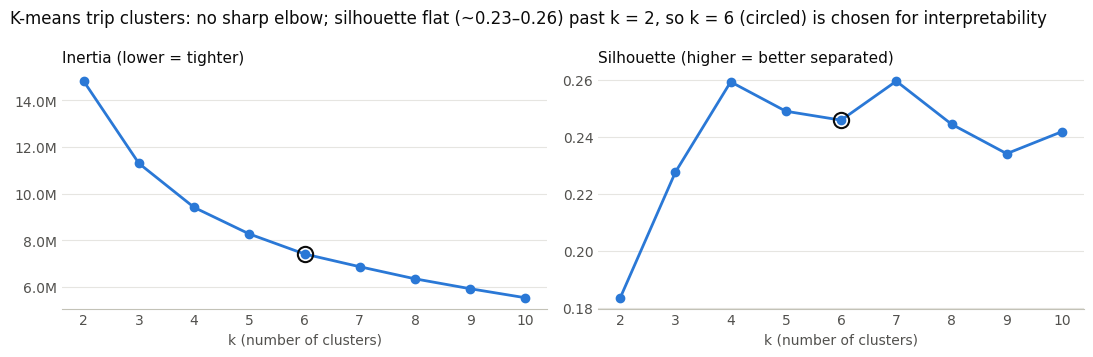

In [56]:
# Choosing k: inertia on all trips, silhouette on a 20k-trip sample (silhouette is O(n²)); takes about a minute on two years of trips
silhouette_sample = np.random.default_rng(0).choice(len(X_trips), 20_000, replace=False)
rows = []
for k in range(2, 11):
    km = KMeans(k, n_init=4, random_state=0).fit(X_trips)
    rows.append({"k": k, "inertia": km.inertia_,
                 "silhouette": silhouette_score(X_trips[silhouette_sample], km.labels_[silhouette_sample])})
trip_k_sweep = pd.DataFrame(rows).set_index("k")
display(trip_k_sweep.round(3))

TRIP_K = 6  # chosen for interpretability (scores are flat past k = 2)
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
for ax, col, note in [(axes[0], "inertia", "lower = tighter"), (axes[1], "silhouette", "higher = better separated")]:
    ax.plot(trip_k_sweep.index, trip_k_sweep[col], color=BLUE, lw=2, marker="o", ms=6)
    ax.plot(TRIP_K, trip_k_sweep.loc[TRIP_K, col], marker="o", ms=11, mfc="none", mec=INK, mew=1.5)
    ax.set_title(f"{col.capitalize()} ({note})")
    ax.set(xlabel="k (number of clusters)", xticks=trip_k_sweep.index)
axes[0].yaxis.set_major_formatter(plt.FuncFormatter(lambda x, _: f"{x / 1e6:.1f}M"))
suptitle(fig, "K-means trip clusters: no sharp elbow; silhouette flat (~0.23–0.26) past k = 2, "
              "so k = 6 (circled) is chosen for interpretability")
fig.tight_layout()
plt.show()

k,2,3,4,5,6,7,8,9,10
mean,1.0,0.99,0.99,0.71,0.96,0.72,0.61,0.78,0.88
min,1.0,0.98,0.98,0.58,0.94,0.50,0.42,0.40,0.80


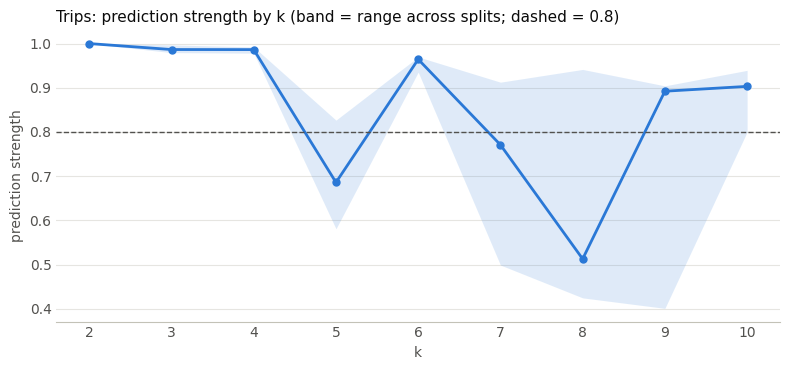

In [57]:
# Choosing k, second criterion: prediction strength (split the trips in half, cluster each half, and check whether
# one half's clusters group the other half the same way; >= 0.8 means the clusters replicate). 100k-trip sample
ps_trip_rows = np.random.default_rng(3).choice(len(X_trips), 100_000, replace=False)
ps_trips = prediction_strength(X_trips[ps_trip_rows], range(2, 11), n_splits=5)
display(ps_trips.groupby("k")["prediction strength"].agg(["mean", "min"]).round(2).T)
stability_curve(ps_trips, "k", "prediction strength", "k", "prediction strength",
                "Trips: prediction strength by k (band = range across splits; dashed = 0.8)", reference=0.8, logx=False)
plt.show()

**Step 3: fit and name.** => Add commentary

In [58]:
# Fit k = 6 trip purposes and name them from their profiles
trip_km = KMeans(TRIP_K, n_init=10, random_state=0).fit(X_trips)  # frozen; labels other quarters later
trips_train["purpose_id"] = trip_km.labels_

trip_profile = trips_train.groupby("purpose_id").agg(
    trips=("duration", "size"), median_min=("duration", "median"), median_km=("dist_km", "median"),
    median_kmh=("speed_kmh", "median"), round_trip=("round_trip", "mean"), weekend=("weekend", "mean"),
    am_peak=("am_peak", "mean"), median_hour=("hour", "median"),
    casual=("casual", "mean"), electric=("electric", "mean"),  # held out: validation only
)
purpose_names = name_by_rules(trip_profile, [
    ("Round trip (leisure)",   "round_trip", "max"),
    ("Slow one-way (leisure)", "median_kmh", "min"),
    ("Weekend utility",        "weekend",    "max"),
    ("Weekday AM & midday",    "am_peak",    "max"),
    ("Weekday PM, longer",     "median_km",  "max"),
    ("Weekday PM, short hop",  None,         None),
])
PURPOSES = ["Weekday AM & midday", "Weekday PM, longer", "Weekday PM, short hop",
            "Weekend utility", "Slow one-way (leisure)", "Round trip (leisure)"]
LEISURE = ["Slow one-way (leisure)", "Round trip (leisure)"]  # the two purposes with ~30% casual riders
trips_train["purpose"] = pd.Categorical(trips_train["purpose_id"].map(purpose_names), categories=PURPOSES, ordered=True)

trip_profile = trip_profile.rename(index=purpose_names).loc[PURPOSES]
trip_profile.insert(1, "share", trip_profile["trips"] / trip_profile["trips"].sum())
percent_cols = ["share", "round_trip", "weekend", "am_peak", "casual", "electric"]
display(trip_profile.style.format("{:.0%}", subset=percent_cols)
        .format({"trips": "{:,}", "median_km": "{:.2f}", "median_kmh": "{:.1f}", "median_min": "{:.0f}", "median_hour": "{:.0f}"}))
print(f"Overall casual share: {trips_train['casual'].mean():.0%} | overall electric share: {trips_train['electric'].mean():.0%}")

,trips,share,median_min,median_km,median_kmh,round_trip,weekend,am_peak,median_hour,casual,electric
purpose_id,,,,,,,,,,,
Weekday AM & midday,"629,364",0.250600,8,1.49,10.9,0.000000,0.000000,0.593291,9,0.028603,0.640702
"Weekday PM, longer","459,939",0.183139,15,2.71,11.0,0.000000,0.033237,0.013180,17,0.082065,0.672515
"Weekday PM, short hop","602,319",0.239831,7,1.08,9.9,0.000000,0.000772,0.000000,17,0.034309,0.625637
Weekend utility,"493,458",0.196485,9,1.53,10.2,0.000000,1.000000,0.000000,14,0.108003,0.635191
Slow one-way (leisure),"231,990",0.092374,34,1.41,2.7,0.000000,0.344222,0.043342,15,0.268279,0.423122
Round trip (leisure),"94,357",0.037571,27,0.00,0.0,1.000000,0.345730,0.056519,16,0.279396,0.548332


Overall casual share: 9% | overall electric share: 62%


In [59]:
# Fit k = 6 trip purposes and name them from their profiles
trip_km = KMeans(TRIP_K, n_init=10, random_state=0).fit(X_trips)  # frozen; labels the test quarters later
trips_train["purpose_id"] = trip_km.labels_

TRIP_PROFILE = dict(  # also used to profile the GMM clusters (2.2)
    trips=("duration", "size"), median_min=("duration", "median"), median_km=("dist_km", "median"),
    median_kmh=("speed_kmh", "median"), round_trip=("round_trip", "mean"), weekend=("weekend", "mean"),
    am_peak=("am_peak", "mean"), median_hour=("hour", "median"),
    casual=("casual", "mean"), electric=("electric", "mean"),  # held out: validation only
)
TRIP_NAME_RULES = [  # also used to name the GMM clusters (2.2)
    ("Round trip (leisure)",   "round_trip", "max"),
    ("Slow one-way (leisure)", "median_kmh", "min"),
    ("Weekend utility",        "weekend",    "max"),
    ("Weekday AM & midday",    "am_peak",    "max"),
    ("Weekday PM, longer",     "median_km",  "max"),
    ("Weekday PM, short hop",  None,         None),
]
trip_profile = trips_train.groupby("purpose_id").agg(**TRIP_PROFILE)
purpose_names = name_by_rules(trip_profile, TRIP_NAME_RULES)
PURPOSES = ["Weekday AM & midday", "Weekday PM, longer", "Weekday PM, short hop",
            "Weekend utility", "Slow one-way (leisure)", "Round trip (leisure)"]
LEISURE = ["Slow one-way (leisure)", "Round trip (leisure)"]  # the two purposes with ~30% casual riders
trips_train["purpose"] = pd.Categorical(trips_train["purpose_id"].map(purpose_names), categories=PURPOSES, ordered=True)

trip_profile = trip_profile.rename(index=purpose_names).loc[PURPOSES]
trip_profile.insert(1, "share", trip_profile["trips"] / trip_profile["trips"].sum())
percent_cols = ["share", "round_trip", "weekend", "am_peak", "casual", "electric"]
display(trip_profile.style.format("{:.0%}", subset=percent_cols)
        .format({"trips": "{:,}", "median_km": "{:.2f}", "median_kmh": "{:.1f}", "median_min": "{:.0f}", "median_hour": "{:.0f}"}))
print(f"Overall casual share: {trips_train['casual'].mean():.0%} | overall electric share: {trips_train['electric'].mean():.0%}")

,trips,share,median_min,median_km,median_kmh,round_trip,weekend,am_peak,median_hour,casual,electric
purpose_id,,,,,,,,,,,
Weekday AM & midday,"629,364",0.250600,8,1.49,10.9,0.000000,0.000000,0.593291,9,0.028603,0.640702
"Weekday PM, longer","459,939",0.183139,15,2.71,11.0,0.000000,0.033237,0.013180,17,0.082065,0.672515
"Weekday PM, short hop","602,319",0.239831,7,1.08,9.9,0.000000,0.000772,0.000000,17,0.034309,0.625637
Weekend utility,"493,458",0.196485,9,1.53,10.2,0.000000,1.000000,0.000000,14,0.108003,0.635191
Slow one-way (leisure),"231,990",0.092374,34,1.41,2.7,0.000000,0.344222,0.043342,15,0.268279,0.423122
Round trip (leisure),"94,357",0.037571,27,0.00,0.0,1.000000,0.345730,0.056519,16,0.279396,0.548332


Overall casual share: 9% | overall electric share: 62%


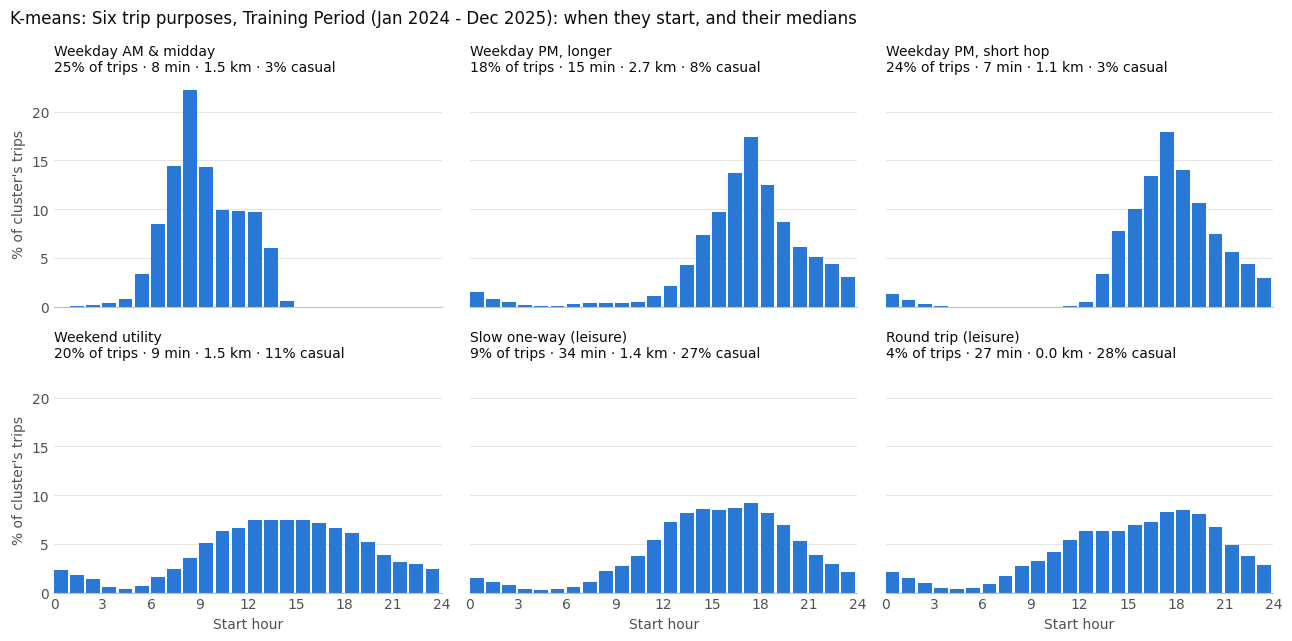

In [60]:
# When each purpose starts, with its medians in the panel title (casual share was not a clustering input)
fig, axes = plt.subplots(2, 3, figsize=(13, 6.5), sharex=True, sharey=True)
for ax, (purpose, r) in zip(axes.flat, trip_profile.loc[PURPOSES].iterrows()):
    by_hour = trips_train.loc[trips_train["purpose"] == purpose, "hour"].value_counts(normalize=True).reindex(range(24), fill_value=0)
    ax.bar(by_hour.index, by_hour.values * 100, width=0.85, align="edge", color=BLUE)
    ax.set_title(f"{purpose}\n{r.share:.0%} of trips · {r.median_min:.0f} min · {r.median_km:.1f} km · {r.casual:.0%} casual",
                 fontsize=10)
for ax in axes[-1]:
    ax.set(xlim=(0, 24), xticks=range(0, 25, 3), xlabel="Start hour")
for ax in axes[:, 0]:
    ax.set_ylabel("% of cluster's trips")
suptitle(fig, f"K-means: Six trip purposes, {TRAIN_LABEL}: when they start, and their medians")
fig.tight_layout()
plt.show()


#### Stage 2: describe each station

**Step 4: one row per station**: the share of its trip ends (starts + ends) in each purpose, its weekday AM (06–09) and PM (15–18) net flow, (arrivals − departures) / (arrivals + departures), its volume and casual share. Stations with fewer than 200 trip ends are dropped. The station clusterings below are built from this table.

In [61]:
# Stage 2 · one row per station: purpose mix, peak net flow, volume, casual share, location (training quarters)
ends_train = trip_ends(trips_train, extra=("purpose", "casual", "quarter"))
MIN_ENDS = 200             # trip ends over the training period
MIN_ENDS_PER_QUARTER = 50  # and in every training quarter, so each fitted station's mix covers every season
ends_per_quarter = pd.crosstab(ends_train["station"], ends_train["quarter"]).reindex(columns=TRAIN_QUARTERS, fill_value=0)
full_coverage = ends_per_quarter.index[(ends_per_quarter >= MIN_ENDS_PER_QUARTER).all(axis=1)]
stations_all_train = station_table(ends_train, trips_train, stations, min_ends=MIN_ENDS)
stations_train = stations_all_train.loc[stations_all_train.index.intersection(full_coverage)].copy()
purpose_counts_train = pd.crosstab(ends_train["station"], ends_train["purpose"])[PURPOSES].loc[stations_train.index]  # trip ends

print(f"{len(stations_all_train)} of {ends_train['station'].nunique()} stations have >= {MIN_ENDS} trip ends. "
      f"{len(stations_train)} of them have >= {MIN_ENDS_PER_QUARTER} in every training quarter and are used to fit the "
      f"station clusters; the other {len(stations_all_train) - len(stations_train)} are assigned to the clusters afterwards.")

301 of 314 stations have >= 200 trip ends. 229 of them have >= 50 in every training quarter and are used to fit the station clusters; the other 72 are assigned to the clusters afterwards.


### Station clusters by the types of rides they serve

Stations are clustered on **ride-type mix**: the share of each station's rides (trips starting or ending there) in each of the six ride clusters.

[↑ Contents](#contents)

In [62]:
# Choosing k for stations clustered on ride-type mix only (standardized shares of the 6 purposes)
ride_mix_scaler = StandardScaler().fit(stations_train[PURPOSES])  # frozen; places other quarters' stations in the same space
X_ride_mix = ride_mix_scaler.transform(stations_train[PURPOSES])
ride_mix_k_sweep = kmeans_vs_ward(X_ride_mix, range(2, 9))
display(ride_mix_k_sweep.round(3))
print("k = 2 only splits leisure stations from the rest; k = 4 has the best Ward agreement past that and reads cleanly.")

,silhouette,ARI vs Ward,cluster sizes
k,,,
2,0.486,0.791,"[188, 41]"
3,0.242,0.502,"[99, 98, 32]"
4,0.282,0.543,"[110, 55, 33, 31]"
5,0.283,0.496,"[105, 55, 37, 28, 4]"
6,0.294,0.520,"[105, 57, 36, 16, 13, 2]"
7,0.280,0.529,"[69, 53, 46, 30, 16, 13, 2]"
8,0.286,0.506,"[66, 46, 34, 29, 23, 16, 13, 2]"


k = 2 only splits leisure stations from the rest; k = 4 has the best Ward agreement past that and reads cleanly.


In [63]:
# Fit k = 4 ride-mix station clusters and name them from their profiles
RIDE_MIX_K = 4
ride_mix_km = KMeans(RIDE_MIX_K, n_init=50, random_state=0).fit(X_ride_mix)  # frozen; assigns other quarters
stations_train["mix_id"] = ride_mix_km.labels_
mix_profile = stations_train.groupby("mix_id")[PURPOSES].median()
mix_profile["leisure"] = mix_profile[LEISURE].sum(axis=1)
RIDE_MIX_RULES = [  # also used by the scorecard (section 8) to name refitted clusters
    ("Leisure & parks",           "leisure",             "max"),
    ("Daytime commute",           "Weekday AM & midday", "max"),
    ("Longer-trip neighbourhood", "Weekday PM, longer",  "max"),
    ("Short-hop core",            None,                  None),
]
ride_mix_names = name_by_rules(mix_profile, RIDE_MIX_RULES)
MIX_TYPES = ["Daytime commute", "Short-hop core", "Longer-trip neighbourhood", "Leisure & parks"]
stations_train["mix_type"] = pd.Categorical(stations_train["mix_id"].map(ride_mix_names), categories=MIX_TYPES, ordered=True)
# Bootstrap label confidence: share of 200 resamples of each station's trip ends that keep its cluster (< 80% = borderline)
stations_train["confidence"] = bootstrap_confidence(purpose_counts_train.to_numpy(), stations_train["mix_id"].to_numpy(),
                                                 ride_mix_scaler, ride_mix_km.cluster_centers_)

In [64]:
# Share of trip ends in each purpose, pooled over each cluster's stations (trip-end-weighted), with held-out checks
def _plain(idx):
    """Replace a categorical index with a plain one (avoids a pandas bug on Python 3.12+)."""
    return pd.Index(idx.tolist(), name=idx.name)

ends_by_mix_type = ends_train.merge(stations_train[["mix_type"]], left_on="station", right_index=True,
                                 how="left", validate="many_to_one")
dropped = ends_by_mix_type["mix_type"].isna().mean()
if dropped:
    print(f"Note: {dropped:.1%} of trip ends are at stations with no mix_type and are excluded")
ends_by_mix_type = ends_by_mix_type.dropna(subset=["mix_type"])

mix_share = pd.crosstab(ends_by_mix_type["mix_type"], ends_by_mix_type["purpose"], normalize="index")
mix_share.index, mix_share.columns = _plain(mix_share.index), _plain(mix_share.columns)
mix_share = mix_share.reindex(columns=PURPOSES, fill_value=0).reindex(MIX_TYPES)

# Same base as mix_share, so the ratio table compares like with like
system_mix = ends_by_mix_type["purpose"].value_counts(normalize=True)
system_mix.index = _plain(system_mix.index)
system_mix = system_mix.reindex(PURPOSES, fill_value=0)

stations_counts = stations_train["mix_type"].value_counts()
stations_counts.index = _plain(stations_counts.index)
stations_counts = stations_counts.reindex(MIX_TYPES, fill_value=0)

system_shares = ends_by_mix_type["mix_type"].value_counts(normalize=True)
system_shares.index = _plain(system_shares.index)
system_shares = system_shares.reindex(MIX_TYPES, fill_value=0)

# Held-out checks: NOT clustering inputs. These are medians across stations, not trip-end-weighted
checks = stations_train.groupby("mix_type", observed=True)[["am_net", "pm_net", "casual"]].median().add_prefix("check_")
checks.index = _plain(checks.index)

mix_summary = (pd.DataFrame({"stations": stations_counts, "share_of_system_rides": system_shares})
               .join(mix_share)
               .join(checks))

display(mix_summary.style
        .format("{:.0%}", subset=["share_of_system_rides", *PURPOSES, "check_casual"], na_rep="–")
        .format("{:+.2f}", subset=["check_am_net", "check_pm_net"], na_rep="–"))
display((mix_share / system_mix).style.format("{:.2f}×", na_rep="–")
        .set_caption("Share of trip ends relative to the system-wide mix (1.00× = same)"))

for name in MIX_TYPES:
    busiest = (stations_train[stations_train["mix_type"] == name]
               .nlargest(6, "trip_ends")["Station_Name"]
               .astype("string").fillna("(name unknown)"))
    print(f"{str(name):27s} e.g. {'; '.join(busiest)}")

Note: 7.6% of trip ends are at stations with no mix_type and are excluded


,stations,share_of_system_rides,Weekday AM & midday,"Weekday PM, longer","Weekday PM, short hop",Weekend utility,Slow one-way (leisure),Round trip (leisure),check_am_net,check_pm_net,check_casual
mix_type,,,,,,,,,,,
Daytime commute,33,21%,36%,17%,25%,14%,6%,2%,+0.55,-0.38,6%
Short-hop core,110,59%,24%,16%,26%,21%,9%,3%,-0.27,+0.08,7%
Longer-trip neighbourhood,55,16%,19%,27%,18%,22%,9%,5%,-0.40,+0.16,8%
Leisure & parks,31,4%,9%,26%,7%,17%,24%,17%,-0.14,+0.03,20%


purpose,Weekday AM & midday,"Weekday PM, longer","Weekday PM, short hop",Weekend utility,Slow one-way (leisure),Round trip (leisure)
mix_type,,,,,,
Daytime commute,1.41×,0.92×,1.05×,0.73×,0.68×,0.48×
Short-hop core,0.96×,0.88×,1.10×,1.07×,1.01×,0.82×
Longer-trip neighbourhood,0.77×,1.47×,0.74×,1.13×,0.95×,1.40×
Leisure & parks,0.35×,1.41×,0.31×,0.88×,2.60×,4.58×


Daytime commute             e.g. University City Station; Amtrak 30th Street Station; 34th & Spruce; 19th & Lombard; 30th Street Station East; 21st & Catharine
Short-hop core              e.g. 15th & Spruce; 23rd & South; 17th & Locust; 4th & Bainbridge; 11th & Market; 12th & Chestnut
Longer-trip neighbourhood   e.g. Moyamensing & Tasker; Point Breeze & Tasker; 18th & Fernon, Aquinas Center; 8th & Mifflin, Bok Building; Welcome Park, NPS; Race Street Pier
Leisure & parks             e.g. Philadelphia Museum of Art; Schuylkill Banks Pergola; Broad & Diamond; Kelly Drive Grandstand; Ridge & Ferry; Kelly Drive - Strawberry Mansion Bridge


In [65]:
# Export station clusters for supervised evaluation

EXPORTS.mkdir(parents=True, exist_ok=True)

station_profiles = (
    stations_train[["mix_id", "mix_type", "confidence"]]
    .rename_axis("station_id")
    .reset_index()
    .rename(columns={
        "mix_id": "cluster_id",
        "mix_type": "station_cluster",
        "confidence": "cluster_confidence"
    })
)

station_profiles["station_cluster"] = (
    station_profiles["station_cluster"].astype(str)
)

assert station_profiles["station_id"].is_unique

# Save clustering results
output_path = EXPORTS / "station_clusters.parquet"
station_profiles.to_parquet(output_path, index=False)

# Save metadata and source checks
manifest = {
    "version": 1,
    "source": "04_unsupervised_model_training",
    "settings": settings,
    "training_end_exclusive": str(TRAIN_END),
    "shared_manifest_hash": file_hash(
        SHARED / "shared_manifest.json"
    ),
    "files": {
        output_path.name: file_hash(output_path)
    },
    "n_stations": len(station_profiles),
    "cluster_names": MIX_TYPES
}

(EXPORTS / "station_clusters_manifest.json").write_text(
    json.dumps(manifest, indent=2) + "\n"
)

print(f"Exported {len(station_profiles)} station profiles")
display(station_profiles.head())

Exported 229 station profiles


,station_id,cluster_id,station_cluster,cluster_confidence
0,3005,0,Longer-trip neighbourhood,1.0
1,3006,1,Short-hop core,1.0
2,3007,1,Short-hop core,1.0
3,3008,2,Daytime commute,1.0
4,3009,1,Short-hop core,1.0


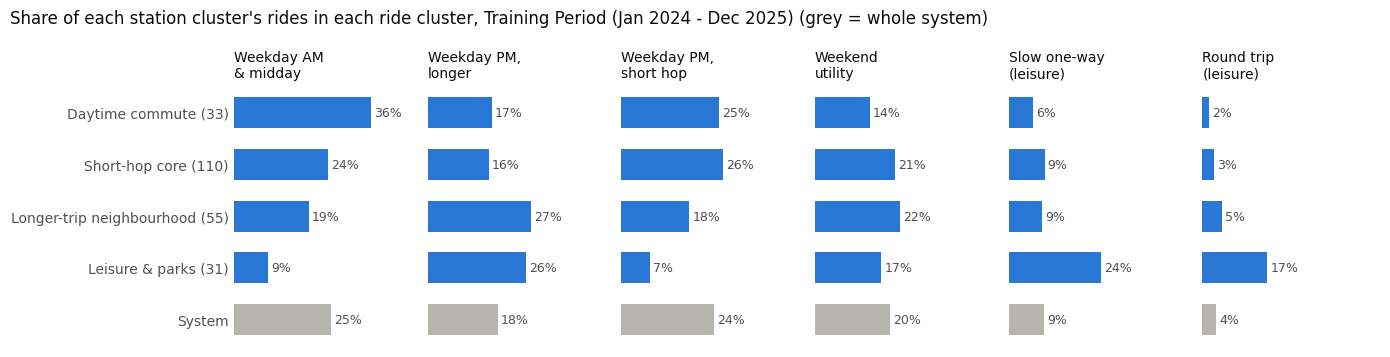

In [66]:
# Ride mix by station cluster vs the whole system (grey bar)
table = pd.concat([mix_share.loc[MIX_TYPES, PURPOSES], system_mix.to_frame("System").T]) * 100
fig, axes = plt.subplots(1, len(PURPOSES), figsize=(14, 3.6), sharey=True)
for ax, purpose in zip(axes, PURPOSES):
    values = table[purpose].to_numpy()
    ax.barh(range(len(values)), values, height=0.6, color=[BLUE] * len(MIX_TYPES) + [REFERENCE])
    label_values(ax, values, "{:.0f}%", offset=0.8)
    ax.set_title(wrap_label(purpose), fontsize=10)
    ax.set_xlim(0, table.to_numpy().max() * 1.3)
    labelled_bars_axis(ax)
axes[0].set_yticks(range(len(table)), [*(f"{t} ({mix_summary.loc[t, 'stations']})" for t in MIX_TYPES), "System"])
axes[0].invert_yaxis()
suptitle(fig, f"Share of each station cluster's rides in each ride cluster, {TRAIN_LABEL} (grey = whole system)")
fig.tight_layout()
plt.show()


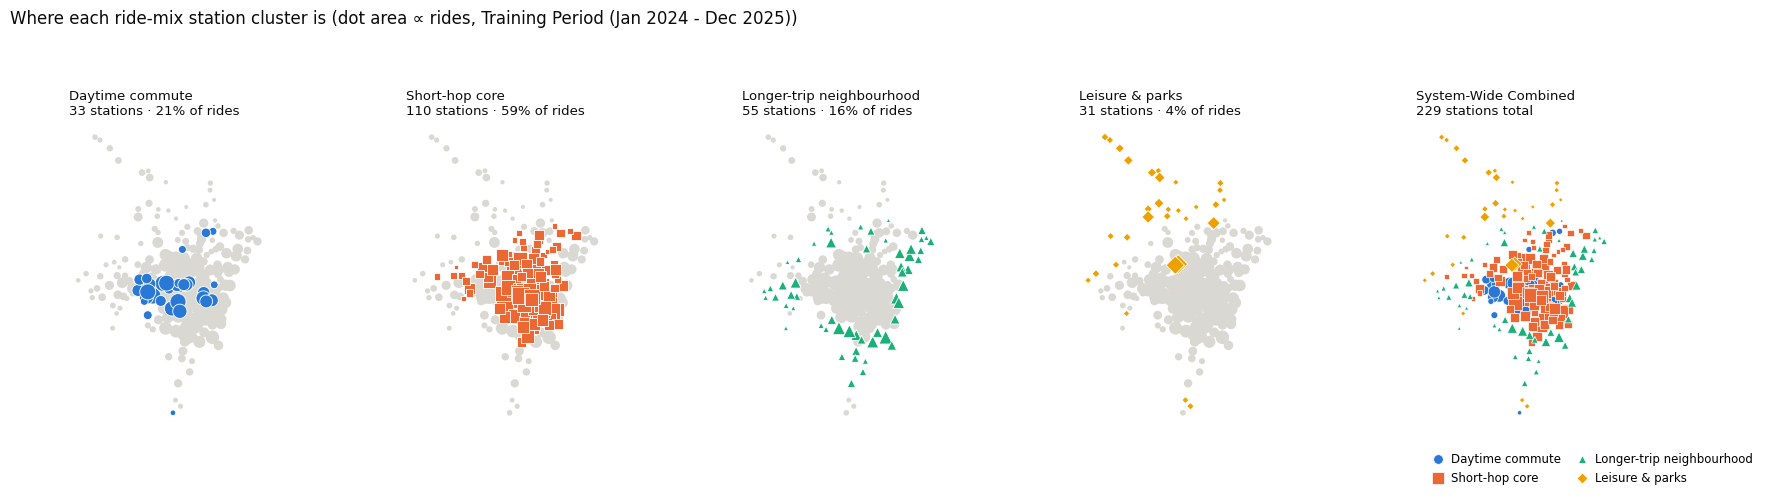

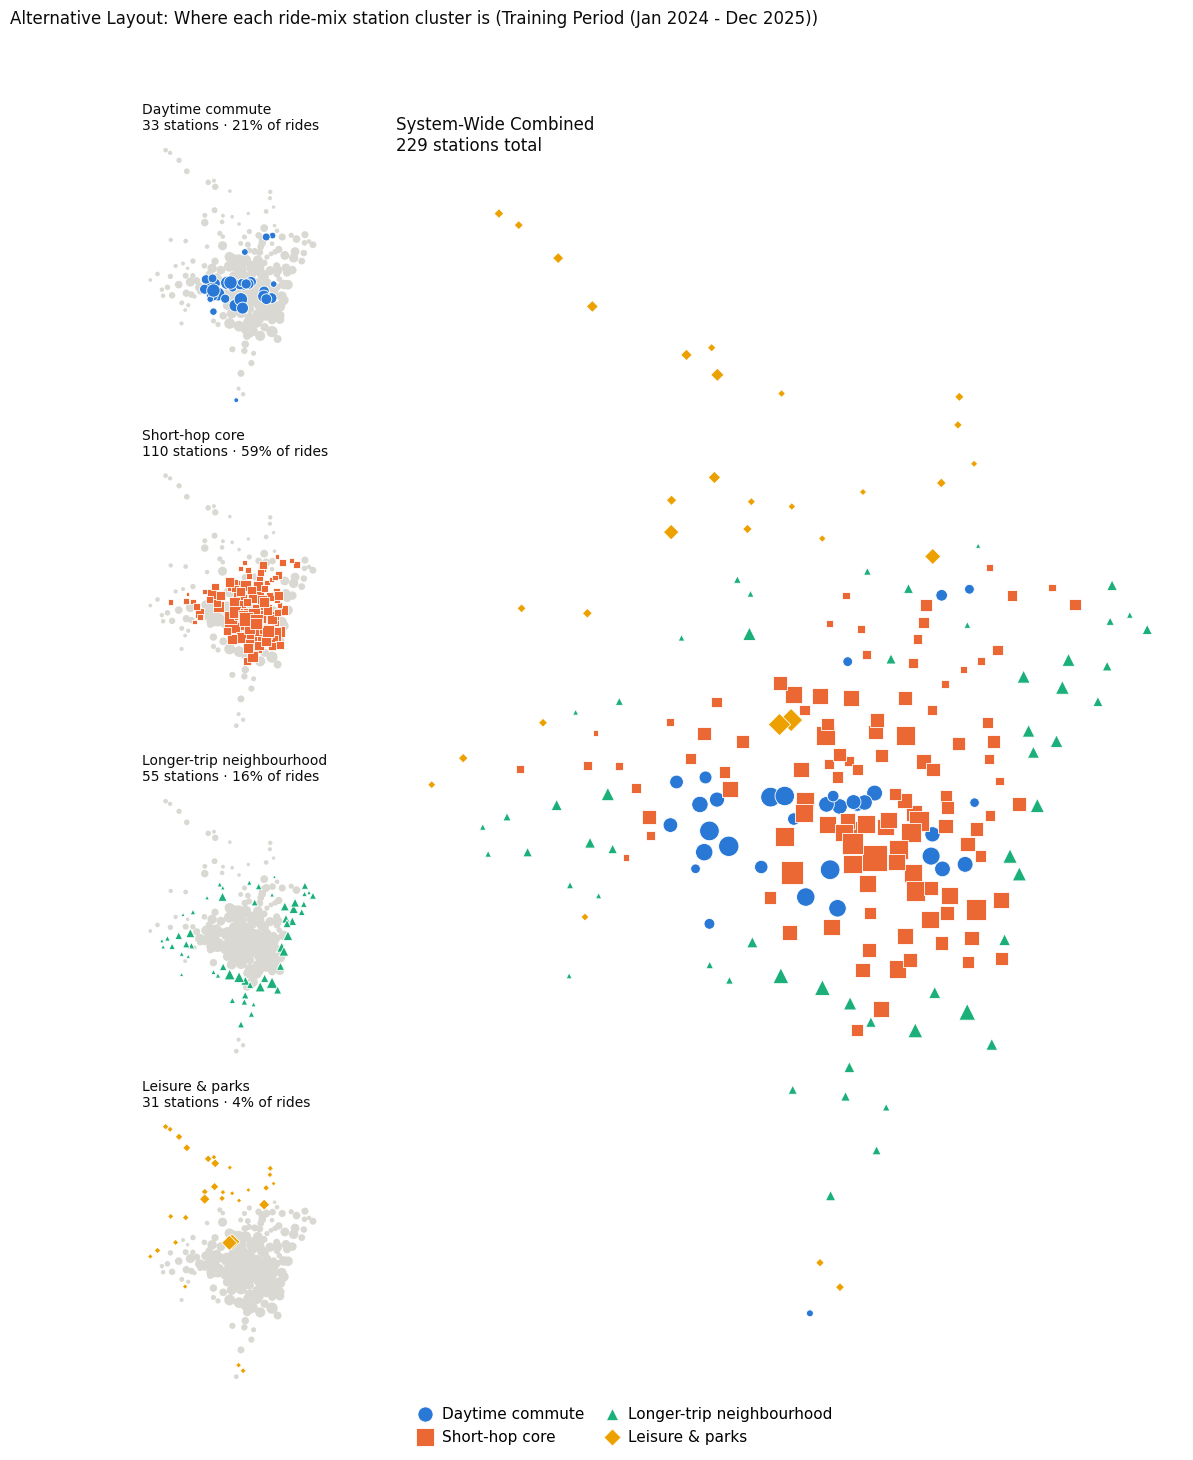

In [67]:
# @title
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec

# --- Plot 1: 5-column by 1-row geographic plots ---
fig, axes = plt.subplots(1, 5, figsize=(18, 5), sharex=True, sharey=True)

# Consistent categorical colors and markers matching the standard style
colors = CATEGORICAL[:len(MIX_TYPES)]
styles = list(zip(MIX_TYPES, colors, MAP_MARKERS[:len(MIX_TYPES)]))

# Standardized station markers sizing based on trip volume
max_size = 220
size = max_size * stations_train["trip_ends"] / stations_train["trip_ends"].max() + 6

# 1. First 4 columns: Individual station clusters with context
for ax, (group, color, marker) in zip(axes[:4], styles):
    on = stations_train["mix_type"] == group
    # Inactive/other stations in the background (grey)
    ax.scatter(stations_train.loc[~on, "lon"], stations_train.loc[~on, "lat"], s=size[~on], color=CONTEXT, lw=0)
    # Active cluster stations
    ax.scatter(stations_train.loc[on, "lon"], stations_train.loc[on, "lat"], s=size[on], color=color, marker=marker, edgecolor=WHITE, lw=0.6)

    # Titles containing counts & percentage of rides
    n_stations = (stations_train['mix_type'] == group).sum()
    share_rides = mix_summary.loc[group, 'share_of_system_rides']
    ax.set_title(f"{group}\n{n_stations} stations · {share_rides:.0%} of rides", fontsize=9.5)

# 2. 5th column: Combined system-wide view
ax_comb = axes[4]
for group, color, marker in styles:
    on = stations_train["mix_type"] == group
    # Plot with slightly smaller points to minimize overlap in the dense core
    ax_comb.scatter(stations_train.loc[on, "lon"], stations_train.loc[on, "lat"], s=size[on] * 0.6, color=color, marker=marker, edgecolor=WHITE, lw=0.5, label=group)

ax_comb.legend(loc="upper left", bbox_to_anchor=(0, -0.05), ncol=2, handletextpad=0.1, columnspacing=0.8, fontsize=8.5)
ax_comb.set_title(f"System-Wide Combined\n{len(stations_train)} stations total", fontsize=9.5)

# Apply aspect ratio, formatting, and clean layout
for ax in axes:
    ax.set_aspect(MAP_ASPECT)
    bare(ax)

# Set main title and adjust layout to avoid overlaps with the tall titles
suptitle(fig, f"Where each ride-mix station cluster is (dot area ∝ rides, {TRAIN_LABEL})", y=0.98)
fig.tight_layout(rect=[0, 0, 1, 0.90])
plt.show()


# --- Plot 2: 4-row by 1-column (left) + 1 large combined (right) ---
fig2 = plt.figure(figsize=(12, 15))
# GridSpec with 4 rows and 2 columns, making the right column larger
gs = GridSpec(4, 2, width_ratios=[1, 1.8], figure=fig2)

axes_left = [fig2.add_subplot(gs[i, 0]) for i in range(4)]
ax_comb_large = fig2.add_subplot(gs[:, 1])

# Left side: 4 individual plots
for ax, (group, color, marker) in zip(axes_left, styles):
    on = stations_train["mix_type"] == group
    ax.scatter(stations_train.loc[~on, "lon"], stations_train.loc[~on, "lat"], s=size[~on] * 0.7, color=CONTEXT, lw=0)
    ax.scatter(stations_train.loc[on, "lon"], stations_train.loc[on, "lat"], s=size[on] * 0.7, color=color, marker=marker, edgecolor=WHITE, lw=0.6)

    n_stations = (stations_train['mix_type'] == group).sum()
    share_rides = mix_summary.loc[group, 'share_of_system_rides']
    ax.set_title(f"{group}\n{n_stations} stations · {share_rides:.0%} of rides", fontsize=10)
    ax.set_aspect(MAP_ASPECT)
    bare(ax)

# Right side: 1 large combined plot
for group, color, marker in styles:
    on = stations_train["mix_type"] == group
    # Scale up the markers slightly for the larger map
    ax_comb_large.scatter(stations_train.loc[on, "lon"], stations_train.loc[on, "lat"], s=size[on] * 1.5, color=color, marker=marker, edgecolor=WHITE, lw=0.6, label=group)

ax_comb_large.legend(loc="upper left", bbox_to_anchor=(0, -0.02), ncol=2, handletextpad=0.1, columnspacing=0.8, fontsize=11)
ax_comb_large.set_title(f"System-Wide Combined\n{len(stations_train)} stations total", fontsize=12)
ax_comb_large.set_aspect(MAP_ASPECT)
bare(ax_comb_large)

suptitle(fig2, f"Alternative Layout: Where each ride-mix station cluster is ({TRAIN_LABEL})", y=0.98)
fig2.tight_layout(rect=[0, 0.05, 1, 0.95])
plt.show()


#### <a id="findings-ride-mix"></a>Findings: station clusters by ride type

Provide commentary based on real data split

## Unsupervised: GMM

A different family from k-means: a **probabilistic** model in which each cluster is a Gaussian (an ellipse-shaped cloud, which may be stretched and tilted), and each trip gets a *probability* of belonging to each cluster instead of one hard label. BIC (lower is better) is GMM's own criterion for the number of components. Here k = 6, the same as k-means, so the two can be compared like for like, and each trip's hard GMM label is its most probable component. The components are named from their own profiles: four by the same rules as k-means (round trips, slow one-way, weekend, weekday AM), but the two weekday PM components differ in **start time**, not distance, so they are named *Weekday afternoon* and *Weekday evening*.

This is the first step of the **GMM pipeline**: the GMM trip purposes feed the GMM station types in 3.2.

,BIC,AIC
k,,
2,448800.0,448173.0
3,394308.0,393364.0
4,78363.0,77102.0
5,18859.0,17280.0
6,-13174.0,-15070.0
7,-36668.0,-38882.0
8,-44912.0,-47443.0
9,-62004.0,-64853.0
10,-90999.0,-94165.0


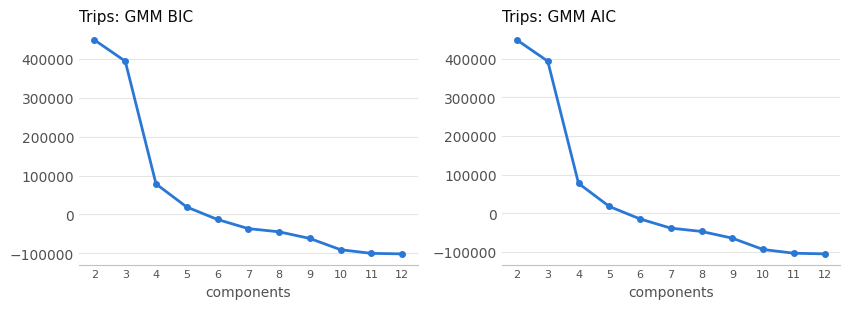

In [68]:
# Trips: BIC / AIC by number of components (50k-trip sample; lower is better)
gmm_trip_rows = np.random.default_rng(4).choice(len(X_trips), 50_000, replace=False)
gmm_trip_sweep = gmm_sweep(X_trips[gmm_trip_rows], range(2, 13))
display(gmm_trip_sweep.round(0))
panel_lines(gmm_trip_sweep, ["BIC", "AIC"], ["Trips: GMM BIC", "Trips: GMM AIC"], "components")
plt.show()

In [69]:
# Fit a 6-component GMM on the 50k-trip sample (frozen; labels every training trip) and name it from its profiles
GMM_TRIP_NAME_RULES = TRIP_NAME_RULES[:4] + [("Weekday afternoon", "median_hour", "min"), ("Weekday evening", None, None)]
GMM_PURPOSES = ["Weekday AM & midday", "Weekday afternoon", "Weekday evening",
                "Weekend utility", "Slow one-way (leisure)", "Round trip (leisure)"]
gmm_trips = fit_gmm(X_trips[gmm_trip_rows], TRIP_K)
gmm_trip_probs = gmm_trips.predict_proba(X_trips)
trips_train["gmm_id"] = gmm_trip_probs.argmax(axis=1)
gmm_trip_profile = trips_train.groupby("gmm_id").agg(**TRIP_PROFILE)
gmm_purpose_names = name_by_rules(gmm_trip_profile, GMM_TRIP_NAME_RULES)
trips_train["gmm_purpose"] = pd.Categorical(trips_train["gmm_id"].map(gmm_purpose_names), categories=GMM_PURPOSES, ordered=True)

gmm_trip_profile = gmm_trip_profile.rename(index=gmm_purpose_names).loc[GMM_PURPOSES]
gmm_trip_profile.insert(1, "share", gmm_trip_profile["trips"] / gmm_trip_profile["trips"].sum())
display(gmm_trip_profile.style.format("{:.0%}", subset=percent_cols)
        .format({"trips": "{:,}", "median_km": "{:.2f}", "median_kmh": "{:.1f}", "median_min": "{:.0f}", "median_hour": "{:.0f}"})
        .set_caption("GMM trip purposes"))
print(f"ARI, GMM vs k-means purposes (all training trips): {adjusted_rand_score(trips_train['purpose_id'], trips_train['gmm_id']):.2f}")

,trips,share,median_min,median_km,median_kmh,round_trip,weekend,am_peak,median_hour,casual,electric
gmm_id,,,,,,,,,,,
Weekday AM & midday,"653,152",0.260072,9,1.58,11.0,0.000000,0.000000,0.553651,9,0.033903,0.648482
Weekday afternoon,"591,954",0.235704,10,1.61,10.3,0.000000,0.000000,0.000000,16,0.051026,0.648631
Weekday evening,"342,637",0.136431,9,1.59,10.6,0.000000,0.000000,0.000000,20,0.055589,0.652507
Weekend utility,"589,066",0.234554,11,1.57,9.6,0.000000,1.000000,0.000000,14,0.146588,0.608784
Slow one-way (leisure),"240,261",0.095667,19,0.94,4.0,0.000000,0.000000,0.116103,13,0.142341,0.463163
Round trip (leisure),"94,357",0.037571,27,0.00,0.0,1.000000,0.345730,0.056519,16,0.279396,0.548332


ARI, GMM vs k-means purposes (all training trips): 0.58


In [70]:
# How certain is each trip's GMM membership? Median top probability, and the share of trips below 0.6
gmm_trip_membership = membership_summary(gmm_trip_probs).assign(gmm_purpose=trips_train["gmm_purpose"].to_numpy())
display(gmm_trip_membership.groupby("gmm_purpose", observed=True).agg(
    median_max_probability=("max probability", "median"), uncertain=("max probability", lambda p: (p < 0.6).mean()),
    median_entropy=("entropy", "median")).loc[GMM_PURPOSES].round(2))

,median_max_probability,uncertain,median_entropy
gmm_purpose,,,
Weekday AM & midday,1.0,0.01,0.01
Weekday afternoon,1.0,0.02,0.00
Weekday evening,1.0,0.03,0.01
Weekend utility,1.0,0.00,0.00
Slow one-way (leisure),1.0,0.04,0.00
Round trip (leisure),1.0,0.00,0.00


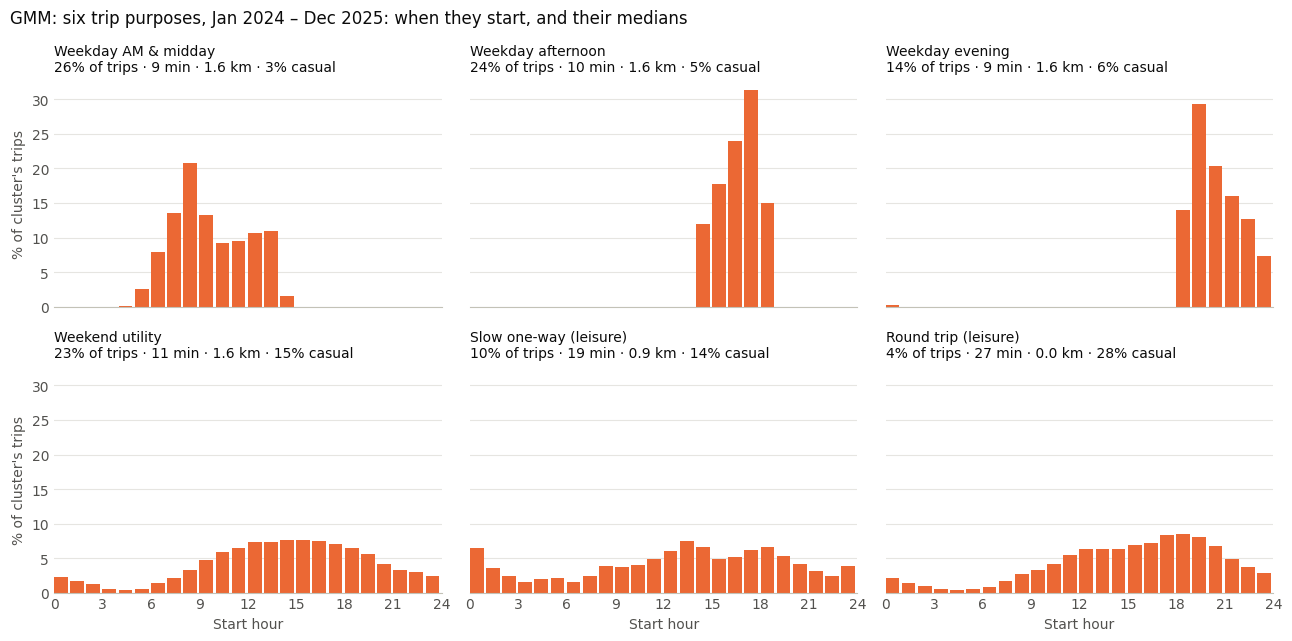

In [71]:
# When each GMM purpose starts, with its medians in the panel title
fig, axes = plt.subplots(2, 3, figsize=(13, 6.5), sharex=True, sharey=True)
for ax, (purpose, r) in zip(axes.flat, gmm_trip_profile.iterrows()):
    by_hour = trips_train.loc[trips_train["gmm_purpose"] == purpose, "hour"].value_counts(normalize=True).reindex(range(24), fill_value=0)
    ax.bar(by_hour.index, by_hour.values * 100, width=0.85, align="edge", color=ORANGE)
    ax.set_title(f"{purpose}\n{r.share:.0%} of trips · {r.median_min:.0f} min · {r.median_km:.1f} km · {r.casual:.0%} casual",
                 fontsize=10)
for ax in axes[-1]:
    ax.set(xlim=(0, 24), xticks=range(0, 25, 3), xlabel="Start hour")
for ax in axes[:, 0]:
    ax.set_ylabel("% of cluster's trips")
suptitle(fig, "GMM: six trip purposes, Jan 2024 – Dec 2025: when they start, and their medians")
fig.tight_layout()
plt.show()

#### <a id="findings-trip-gmm"></a>Findings: GMM trip purposes

**Six GMM trip purposes:**
- **Weekday AM & midday:** 29% of trips (k-means: 25%), median start 09:00, 4% casual.
- **Weekday afternoon:** 26%, median start 16:00, 1.6 km.
- **Weekday evening:** 14%, median start 20:00, 1.6 km.
- **Weekend utility:** 22%.
- **Slow one-way (leisure):** 5% (k-means: 9%), 41 min at 1.6 km/h: a narrower, more extreme group.
- **Round trips (leisure):** 4%, identical to k-means.

**How it differs from k-means.** Agreement is **ARI 0.61**. Every k-means round trip, weekend trip and weekday AM trip lands in the matching GMM group; GMM's AM and weekend groups are larger because they also take in some PM and slow one-way trips. The difference is in the weekday PM trips: **k-means splits them by distance** (longer vs short hop), **GMM splits them by time** (afternoon vs evening; both groups have a median of about 1.6 km). The four weekday and weekend GMM groups all have about the same median distance; GMM's Gaussians line up with the time and 0/1 features rather than with distance.

### <a id="station-gmm"></a>3.2 GMM

The second step of the **GMM pipeline**. Each station is described by its shares of the six **GMM** trip purposes (2.2), standardized, and clustered with a Gaussian mixture.

In [72]:
# Calculate the GMM ride mix for each station now that gmm_purpose exists
gmm_ends = trip_ends(trips_train, extra=("gmm_purpose",))
gmm_counts_train = plain_columns(pd.crosstab(gmm_ends["station"], gmm_ends["gmm_purpose"])[GMM_PURPOSES].loc[stations_train.index])
gmm_shares_train = gmm_counts_train.div(gmm_counts_train.sum(axis=1), axis=0)

# GMM pipeline, stage 2: BIC by number of components on the standardized GMM ride mix (lower is better)
gmm_mix_scaler = StandardScaler().fit(gmm_shares_train[GMM_PURPOSES])  # frozen; places the test quarters in the same space
X_gmm_mix = gmm_mix_scaler.transform(gmm_shares_train[GMM_PURPOSES])
gmm_mix_sweep = pd.concat({cov: gmm_sweep(X_gmm_mix, range(1, 9), covariance_type=cov, n_init=5)["BIC"]
                           for cov in ["full", "diag"]}, axis=1)
display(gmm_mix_sweep.round(0).rename_axis("components").add_prefix("BIC, "))

,"BIC, full","BIC, diag"
components,,
1,1954.0,3964.0
2,1588.0,3347.0
3,1612.0,3034.0
4,1697.0,2956.0
5,1774.0,2958.0
6,1874.0,2926.0
7,1991.0,2936.0
8,2049.0,2932.0


In [73]:
# Fit 4 components (frozen) and name them from their profiles; membership probability for every station
GMM_STATION_K = RIDE_MIX_K
GMM_STATION_RULES = [("Leisure & parks", "leisure", "max"), ("Daytime commute", "Weekday AM & midday", "max"),
                     ("Weekday utility", "leisure", "min"), ("Mixed weekday & leisure", None, None)]
GMM_TYPES = ["Daytime commute", "Weekday utility", "Mixed weekday & leisure", "Leisure & parks"]
gmm_station_model = fit_gmm(X_gmm_mix, GMM_STATION_K, covariance_type="diag", n_init=10)
gmm_station_own_probs = gmm_station_model.predict_proba(X_gmm_mix)
stations_train["gmm_id"] = gmm_station_own_probs.argmax(axis=1)
stations_train["gmm_max_prob"] = gmm_station_own_probs.max(axis=1)
gmm_station_profile = gmm_shares_train.groupby(stations_train["gmm_id"])[GMM_PURPOSES].median()
gmm_station_profile["leisure"] = gmm_station_profile[LEISURE].sum(axis=1)
gmm_station_names = name_by_rules(gmm_station_profile, GMM_STATION_RULES)
stations_train["gmm_type"] = pd.Categorical(stations_train["gmm_id"].map(gmm_station_names), categories=GMM_TYPES, ordered=True)

# Share of rides in each GMM purpose, pooled over each GMM station type, with the same held-out checks as k-means
ends_by_gmm_type = gmm_ends.merge(stations_train[["gmm_type"]], left_on="station", right_index=True)

def _plain(idx):
    return pd.Index(idx.tolist(), name=idx.name)

gmm_mix_share = pd.crosstab(ends_by_gmm_type["gmm_type"], ends_by_gmm_type["gmm_purpose"], normalize="index")
gmm_mix_share.index, gmm_mix_share.columns = _plain(gmm_mix_share.index), _plain(gmm_mix_share.columns)
gmm_mix_share = gmm_mix_share[GMM_PURPOSES]

gmm_system_mix = gmm_ends["gmm_purpose"].value_counts(normalize=True)
gmm_system_mix.index = _plain(gmm_system_mix.index)
gmm_system_mix = gmm_system_mix[GMM_PURPOSES]

stations_counts = stations_train["gmm_type"].value_counts()
stations_counts.index = _plain(stations_counts.index)

system_shares = ends_by_gmm_type["gmm_type"].value_counts(normalize=True)
system_shares.index = _plain(system_shares.index)

checks = stations_train.groupby("gmm_type", observed=True)[["am_net", "casual"]].median().add_prefix("check_")
checks.index = _plain(checks.index)

gmm_summary = (pd.DataFrame({"stations": stations_counts,
                             "share_of_system_rides": system_shares})
               .loc[GMM_TYPES].join(gmm_mix_share)
               .join(checks))
display(gmm_summary.style.format("{:.0%}", subset=["share_of_system_rides"] + GMM_PURPOSES + ["check_casual"])
        .format("{:+.2f}", subset=["check_am_net"]).set_caption("GMM station types"))
print(f"Stations whose top GMM probability is below 0.6: {(stations_train['gmm_max_prob'] < 0.6).mean():.0%}")
for name in GMM_TYPES:
    busiest = stations_train[stations_train["gmm_type"] == name].nlargest(6, "trip_ends")["Station_Name"].fillna("(name unknown)")
    print(f"{name:27s} e.g. {'; '.join(busiest)}")

,stations,share_of_system_rides,Weekday AM & midday,Weekday afternoon,Weekday evening,Weekend utility,Slow one-way (leisure),Round trip (leisure),check_am_net,check_casual
gmm_type,,,,,,,,,,
Daytime commute,23,14%,38%,28%,9%,15%,8%,2%,+0.66,6%
Weekday utility,65,40%,27%,25%,14%,23%,8%,2%,-0.34,6%
Mixed weekday & leisure,98,38%,23%,22%,15%,26%,11%,4%,-0.28,8%
Leisure & parks,43,8%,14%,17%,11%,31%,14%,13%,-0.13,18%


Stations whose top GMM probability is below 0.6: 1%
Daytime commute             e.g. University City Station; 34th & Spruce; 30th Street Station East; 9th & Locust; The Children's Hospital of Philadelphia (CHOP); 36th & Sansom
Weekday utility             e.g. 15th & Spruce; 23rd & South; 17th & Locust; 4th & Bainbridge; Amtrak 30th Street Station; 11th & Market
Mixed weekday & leisure     e.g. 12th & Chestnut; 25th & Locust; 13th & Locust; 11th & Pine, Kahn Park; 16th & Chestnut; 18th & Walnut
Leisure & parks             e.g. Philadelphia Museum of Art; Schuylkill Banks Pergola; Race Street Pier; Foglietta Plaza; Girard Station, MFL; Broad & Cecil B Moore


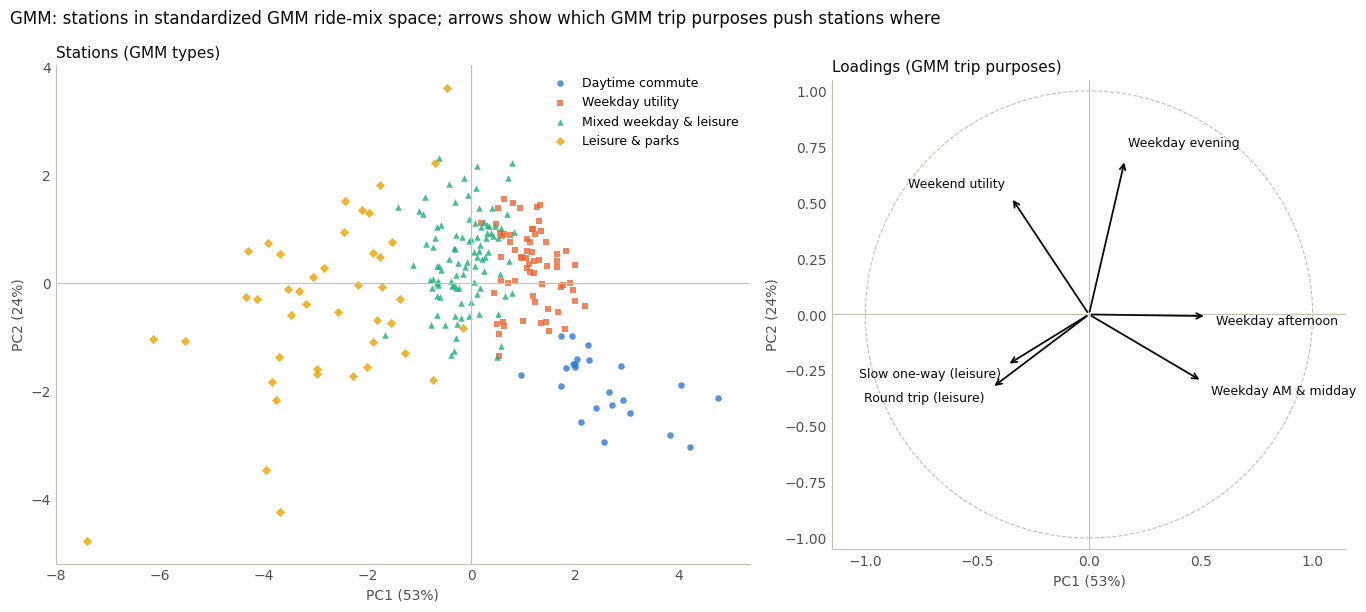

,PC1 (53%),PC2 (24%)
Weekday AM & midday,+0.50,-0.30
Weekday afternoon,+0.53,-0.01
Weekday evening,+0.16,+0.69
Weekend utility,-0.35,+0.52
Slow one-way (leisure),-0.37,-0.23
Round trip (leisure),-0.43,-0.33


In [74]:
# GMM biplot: PCA of the standardized GMM ride mix (the GMM pipeline's station features), coloured by GMM type.
# Same method as the k-means biplot in 3.1.2, so the two pipelines can be read side by side
gmm_pca = PCA().fit(X_gmm_mix)
gmm_scores = gmm_pca.transform(X_gmm_mix)
gmm_var = gmm_pca.explained_variance_ratio_
fig, (ax_points, ax_loadings) = plt.subplots(1, 2, figsize=(14, 6.2), gridspec_kw={"width_ratios": [1.35, 1]})
axis_labels = (f"PC1 ({gmm_var[0]:.0%})", f"PC2 ({gmm_var[1]:.0%})")
for group, color, marker in group_styles(GMM_TYPES):
    on = (stations_train["gmm_type"] == group).to_numpy()
    ax_points.scatter(gmm_scores[on, 0], gmm_scores[on, 1], s=22, color=color, marker=marker, lw=0, alpha=0.8, label=group)
ax_points.legend(loc="best")
ax_points.set(title="Stations (GMM types)", xlabel=axis_labels[0], ylabel=axis_labels[1])
for (lx, ly), name in zip(gmm_pca.components_.T[:, :2], GMM_PURPOSES):
    ax_loadings.annotate("", xy=(lx, ly), xytext=(0, 0), arrowprops={"arrowstyle": "->", "color": INK, "lw": 1.3})
    ax_loadings.text(lx * 1.08, ly * 1.08 + 0.02 * np.sign(ly), name, fontsize=9, color=INK,
                     ha="left" if lx >= 0 else "right", va="center")
ax_loadings.add_patch(plt.Circle((0, 0), 1, fill=False, color=AXIS, lw=0.8, ls="--"))
ax_loadings.set(xlim=(-1.15, 1.15), ylim=(-1.05, 1.05), title="Loadings (GMM trip purposes)", xlabel=axis_labels[0], ylabel=axis_labels[1])
ax_loadings.set_aspect("equal")
for ax in (ax_points, ax_loadings):
    ax.axhline(0, color=AXIS, lw=0.8)
    ax.axvline(0, color=AXIS, lw=0.8)
    ax.grid(False)
    ax.spines["left"].set_visible(True)
suptitle(fig, "GMM: stations in standardized GMM ride-mix space; arrows show which GMM trip purposes push stations where")
fig.tight_layout()
plt.show()
display(pd.DataFrame(gmm_pca.components_[:2].T, index=GMM_PURPOSES, columns=list(axis_labels)).round(2)
        .style.format("{:+.2f}").set_caption("GMM biplot loadings"))

## Evaluating the clusters: importance, failures, sensitivity, stability

Provide commentary

[↑ Contents](#contents)

In [75]:
# Section 4 compares every method with the k-means baselines. Each cell below adds its partitions' summaries
# (clusters, noise share, silhouette, ARI vs k-means) to this dict; the comparison table near the end reads it.
def describe_partition(labels, X, reference, metric: str = "euclidean") -> dict:
    """Clusters, noise share, silhouette and ARI vs a reference partition. Noise (label −1) is excluded from
    silhouette and ARI. With metric="precomputed", X is a square distance matrix."""
    labels = np.asarray(labels)
    core = labels >= 0
    n_clusters = len(set(labels[core]))
    X_core = np.asarray(X)[np.ix_(core, core)] if metric == "precomputed" else np.asarray(X)[core]
    if n_clusters < 2:
        return {"clusters": n_clusters, "noise": 1 - core.mean(), "silhouette": np.nan, "ARI vs k-means": np.nan}
    return {"clusters": n_clusters,
            "noise": 1 - core.mean(),
            "silhouette": silhouette_score(X_core, labels[core], metric=metric),
            "ARI vs k-means": adjusted_rand_score(np.asarray(reference)[core], labels[core])}


method_results = {}  # (stage, method) -> summary
method_results[("stations", "k-means (k = 4)")] = describe_partition(stations_train["mix_id"], X_ride_mix, stations_train["mix_type"])

### Hierarchical clustering (Ward)

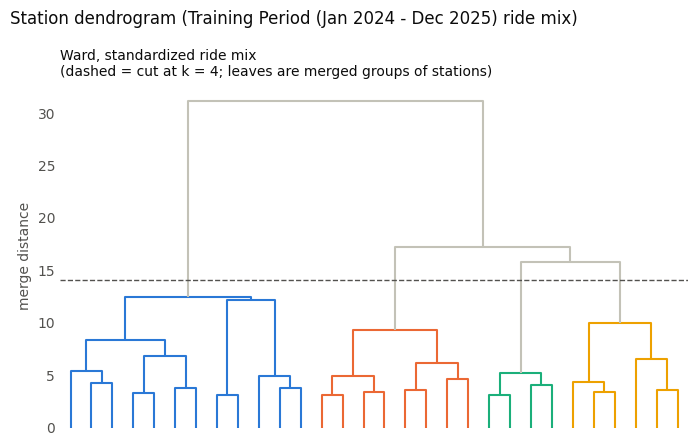

In [76]:
# Stations, hierarchical: Ward on the standardized ride mix (same features as the k-means ride-mix clusters)
ward_link = linkage(X_ride_mix, method="ward")
stations_train["ward4"] = fcluster(ward_link, RIDE_MIX_K, criterion="maxclust")

# Truncated dendrogram, cut (dashed) at the height that yields RIDE_MIX_K clusters
set_link_color_palette(CATEGORICAL)
cut_height = (ward_link[-RIDE_MIX_K, 2] + ward_link[-RIDE_MIX_K + 1, 2]) / 2
fig, ax = plt.subplots(figsize=(7, 4.5))
dendrogram(ward_link, ax=ax, truncate_mode="lastp", p=30, color_threshold=cut_height, above_threshold_color=AXIS,
           no_labels=True)
ax.axhline(cut_height, color=MUTED, lw=1, ls="--")
ax.set_title(f"Ward, standardized ride mix\n(dashed = cut at k = {RIDE_MIX_K}; leaves are merged groups of stations)",
             fontsize=10)
ax.set_ylabel("merge distance")
ax.grid(False)
ax.spines["bottom"].set_visible(False)
suptitle(fig, f"Station dendrogram ({TRAIN_LABEL} ride mix)")
fig.tight_layout()
plt.show()


### Density-based clustering (DBSCAN) on trips and stations

PCA explained variance by component: [0.28  0.214 0.179 0.139 0.104 0.075 0.009]
Keeping 5 components (>= 90% of variance)


,PC1,PC2,PC3,PC4,PC5
log_duration,-0.27,0.71,-0.20,-0.17,0.06
log_dist,0.42,0.63,-0.08,-0.07,0.06
speed_kmh,0.63,-0.12,0.11,0.08,0.13
round_trip,-0.57,-0.10,-0.08,-0.10,0.25
hour_sin,0.16,-0.20,-0.65,-0.08,0.68
hour_cos,-0.07,0.13,0.70,0.03,0.67
weekend,-0.11,0.15,-0.14,0.97,0.06


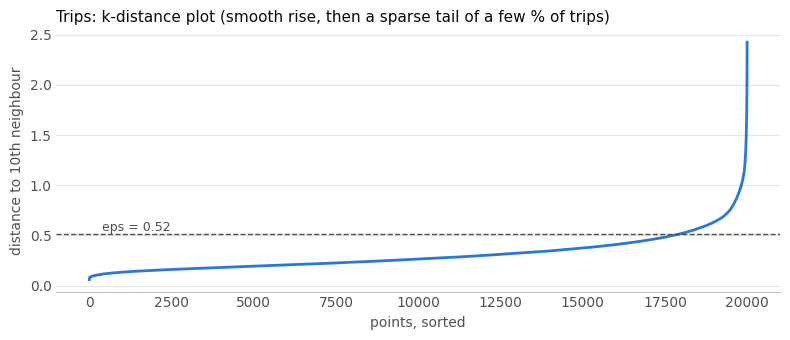

In [77]:
# Trips, density-based: PCA first (density is meaningless across 7 correlated dims), then DBSCAN on a sample
trip_pca = PCA().fit(X_trips)
print("PCA explained variance by component:", np.round(trip_pca.explained_variance_ratio_, 3))
N_TRIP_PCS = int(np.searchsorted(np.cumsum(trip_pca.explained_variance_ratio_), 0.90) + 1)
print(f"Keeping {N_TRIP_PCS} components (>= 90% of variance)")
display(pd.DataFrame(trip_pca.components_[:N_TRIP_PCS].T, index=TRIP_FEATURES,
                     columns=[f"PC{i + 1}" for i in range(N_TRIP_PCS)]).round(2))

density_sample = np.random.default_rng(2).choice(len(X_trips), 20_000, replace=False)
trip_pcs_sample = trip_pca.transform(X_trips[density_sample])[:, :N_TRIP_PCS]
kmeans_on_density_sample = trips_train["purpose"].to_numpy()[density_sample]

# eps from the k-distance curve: distance to the MIN_PTS-th neighbour, sorted. The knee is soft, so the
# 90th percentile is used (leaves ~10% as candidate noise)
MIN_PTS = 2 * N_TRIP_PCS
trip_kdist = k_distance(trip_pcs_sample, MIN_PTS)
EPS_TRIP = float(np.quantile(trip_kdist, 0.90))
k_distance_plot(trip_kdist, EPS_TRIP, MIN_PTS, "Trips: k-distance plot (smooth rise, then a sparse tail of a few % of trips)")
plt.show()

In [78]:
# Trips: DBSCAN (eps from the k-distance plot) on the PCA-reduced sample
trip_dbscan = DBSCAN(eps=EPS_TRIP, min_samples=MIN_PTS).fit_predict(trip_pcs_sample)
result = method_results[("trips (20k sample, PCA)", "DBSCAN")] = describe_partition(
    trip_dbscan, trip_pcs_sample, kmeans_on_density_sample)
sizes = sorted(np.bincount(trip_dbscan[trip_dbscan >= 0]).tolist(), reverse=True)[:8]
print(f"DBSCAN: {result['clusters']} clusters | noise {result['noise']:.0%} | silhouette (non-noise) "
      f"{result['silhouette']:.3f} | ARI vs k-means (non-noise) {result['ARI vs k-means']:.2f} | largest {sizes}")
display(pd.crosstab(pd.Categorical(kmeans_on_density_sample, categories=PURPOSES),
                    np.where(trip_dbscan < 0, "noise", trip_dbscan.astype(str)), rownames=["k-means purpose"],
                    colnames=["DBSCAN cluster"]))

DBSCAN: 9 clusters | noise 5% | silhouette (non-noise) 0.103 | ARI vs k-means (non-noise) 0.28 | largest [13958, 4239, 472, 193, 162, 10, 9, 9]


DBSCAN cluster,0,1,2,3,4,5,6,7,8,noise
k-means purpose,,,,,,,,,,
Weekday AM & midday,4872,0,0,77,0,0,0,0,0,62
"Weekday PM, longer",3521,0,61,0,0,0,0,0,0,150
"Weekday PM, short hop",4476,0,0,116,0,0,0,0,0,70
Weekend utility,0,0,3738,0,0,0,4,0,0,218
Slow one-way (leisure),1089,0,440,0,0,0,5,5,9,318
Round trip (leisure),0,472,0,0,162,10,0,0,0,125


In [79]:
# Stations, density-based: DBSCAN on the standardized ride mix (Training Period points, 6 dims)
MIN_PTS_STATIONS = 2 * len(PURPOSES)
EPS_STATIONS = float(np.quantile(k_distance(X_ride_mix, MIN_PTS_STATIONS), 0.90))
station_dbscan = DBSCAN(eps=EPS_STATIONS, min_samples=MIN_PTS_STATIONS).fit_predict(X_ride_mix)
result = method_results[("stations", "DBSCAN")] = describe_partition(station_dbscan, X_ride_mix, stations_train["mix_type"])
print(f"DBSCAN (eps = {EPS_STATIONS:.2f}, min_samples = {MIN_PTS_STATIONS}): {result['clusters']} clusters | "
      f"noise {result['noise']:.0%} ({(station_dbscan < 0).sum()} stations)")
display(pd.crosstab(stations_train["mix_type"], np.where(station_dbscan < 0, "noise", station_dbscan.astype(str)),
                    rownames=["k-means type"], colnames=["cluster"]))

print("Stations DBSCAN flags as outliers (most distinctive ride mixes), busiest first:")
display(stations_train.loc[station_dbscan < 0, ["Station_Name", "mix_type", "trip_ends"] + PURPOSES]
        .sort_values("trip_ends", ascending=False).head(15)
        .style.format("{:.0%}", subset=PURPOSES).format("{:,}", subset=["trip_ends"]))

DBSCAN (eps = 2.41, min_samples = 12): 1 clusters | noise 2% (5 stations)


cluster,0,noise
k-means type,,
Daytime commute,33,0
Short-hop core,110,0
Longer-trip neighbourhood,55,0
Leisure & parks,26,5


Stations DBSCAN flags as outliers (most distinctive ride mixes), busiest first:


,Station_Name,mix_type,trip_ends,Weekday AM & midday,"Weekday PM, longer","Weekday PM, short hop",Weekend utility,Slow one-way (leisure),Round trip (leisure)
station,,,,,,,,,
3057,Philadelphia Museum of Art,Leisure & parks,"34,632",11%,14%,8%,21%,36%,10%
3326,M.L.K. Drive - Strawberry Mansion Bridge,Leisure & parks,"4,919",2%,17%,0%,13%,37%,31%
3323,Manayunk Bridge,Leisure & parks,"4,123",2%,17%,2%,5%,11%,63%
3356,12th & Normandy,Leisure & parks,"3,057",11%,16%,11%,7%,10%,45%
3278,22nd & Sedgley,Leisure & parks,"1,115",11%,14%,14%,10%,20%,31%


### Comparison of all methods

In [80]:
# Comparison of every method against the k-means baselines
comparison = pd.DataFrame.from_dict(method_results, orient="index")
comparison.index = pd.MultiIndex.from_tuples(comparison.index, names=["stage", "method"])
display(comparison.style.format({"noise": "{:.0%}", "silhouette": "{:.3f}", "ARI vs k-means": "{:.2f}"}, na_rep="—"))
print("Silhouette is computed in each method's own space (PCA for density methods on trips) "
      "and excludes noise, so compare it within a stage, not across stages.")

,,clusters,noise,silhouette,ARI vs k-means
stage,method,,,,
stations,k-means (k = 4),4,0%,0.282,1.00
"trips (20k sample, PCA)",DBSCAN,9,5%,0.103,0.28
stations,DBSCAN,1,2%,—,—


Silhouette is computed in each method's own space (PCA for density methods on trips) and excludes noise, so compare it within a stage, not across stages.


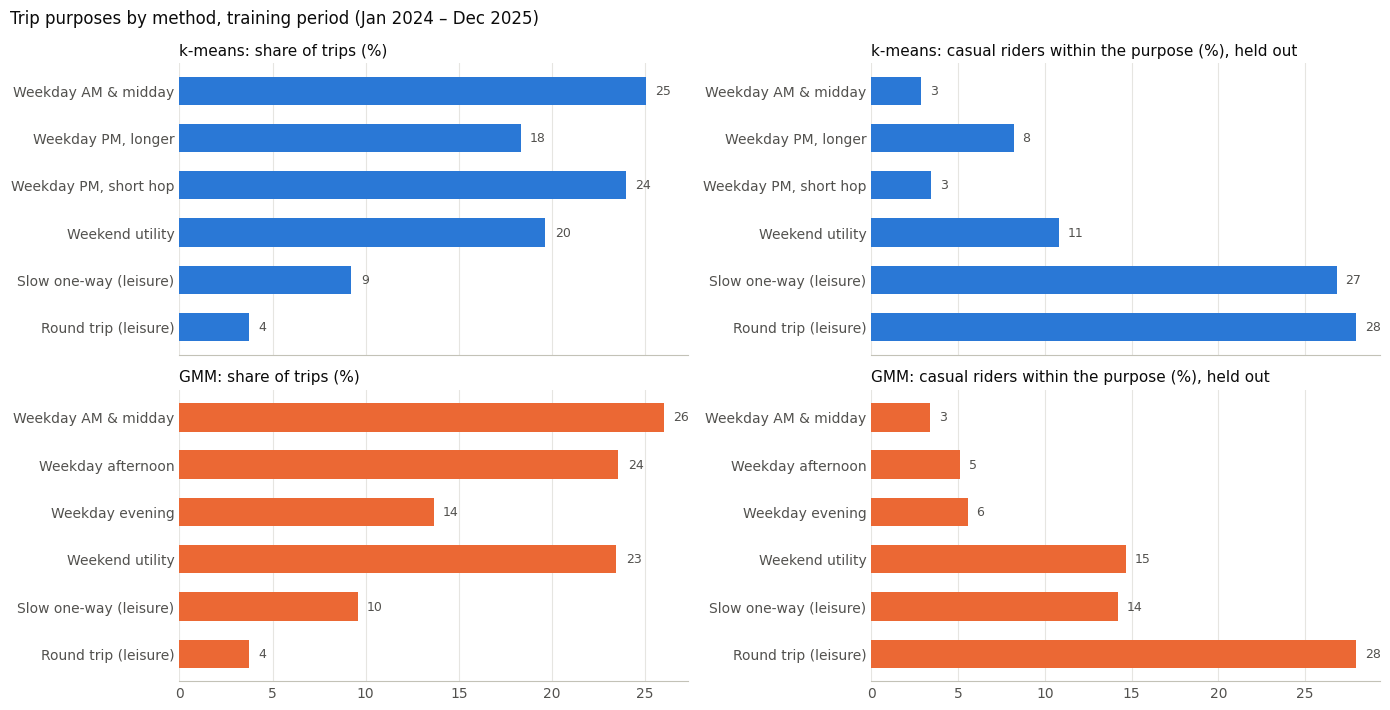

In [81]:
# Trips: share of trips and casual share in each purpose, each method with its own purposes
fig, axes = plt.subplots(2, 2, figsize=(14, 7.2), sharex="col")
for row, (method, column, order, color) in enumerate([("k-means", "purpose", PURPOSES, BLUE), ("GMM", "gmm_purpose", GMM_PURPOSES, ORANGE)]):
    share = trips_train[column].value_counts(normalize=True).reindex(order) * 100
    casual = trips_train.groupby(column, observed=True)["casual"].mean().reindex(order) * 100
    for ax, values, title in [(axes[row, 0], share, "share of trips (%)"),
                              (axes[row, 1], casual, "casual riders within the purpose (%), held out")]:
        ax.barh(range(len(order)), values, height=0.6, color=color)
        label_values(ax, values.to_numpy(), "{:.0f}", offset=0.5)
        ax.set_yticks(range(len(order)), order)
        ax.invert_yaxis()
        vertical_gridlines(ax)
        ax.set_title(f"{method}: {title}")
suptitle(fig, "Trip purposes by method, training period (Jan 2024 – Dec 2025)")
fig.tight_layout()
plt.show()

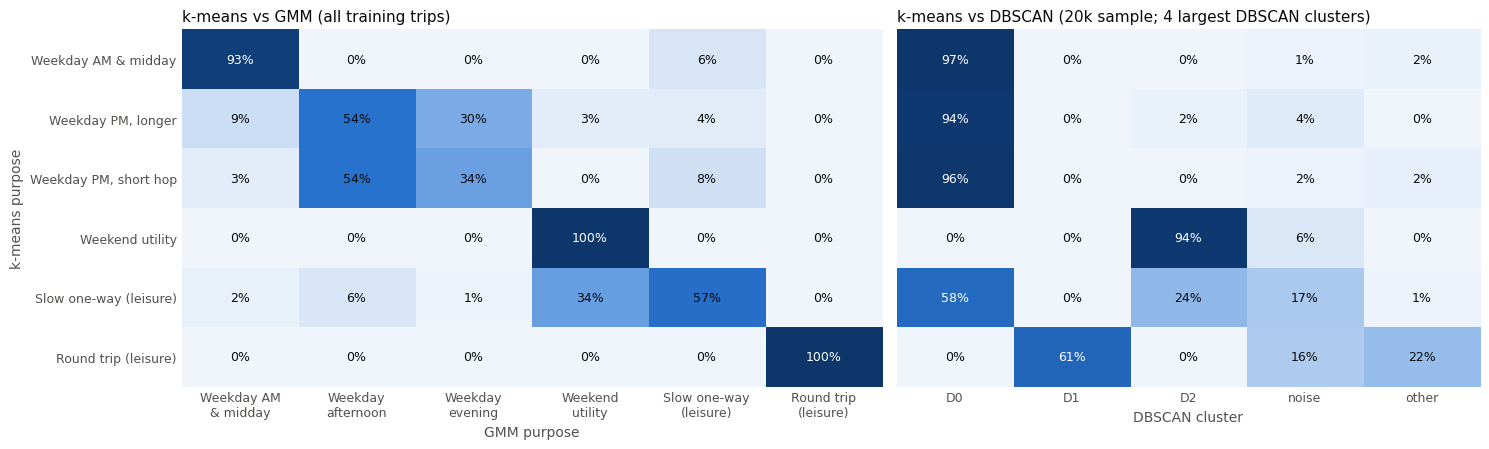

In [82]:
# Trips: where the methods agree. Rows = k-means purpose; each row shows where its trips go (row shares)
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6), gridspec_kw={"width_ratios": [6, 5]})
share_heatmap(pd.crosstab(trips_train["purpose"], trips_train["gmm_purpose"], normalize="index")
              .rename_axis(index="k-means purpose", columns="GMM purpose"), "k-means vs GMM (all training trips)", ax=axes[0])
dbscan_labels = pd.Series(np.where(trip_dbscan < 0, "noise", "D" + trip_dbscan.astype(str)))
dbscan_sizes = dbscan_labels.value_counts()
dbscan_shown = dbscan_labels.where(dbscan_labels.isin(dbscan_sizes.index[:4]) | (dbscan_labels == "noise"), "other")
share_heatmap(pd.crosstab(pd.Categorical(trips_train["purpose"].to_numpy()[density_sample], categories=PURPOSES),
                          dbscan_shown.to_numpy(), normalize="index").rename_axis(index="k-means purpose", columns="DBSCAN cluster"),
              "k-means vs DBSCAN (20k sample; 4 largest DBSCAN clusters)", ax=axes[1])
axes[1].set_yticks([])
axes[1].set_ylabel("")
fig.tight_layout()
plt.show()

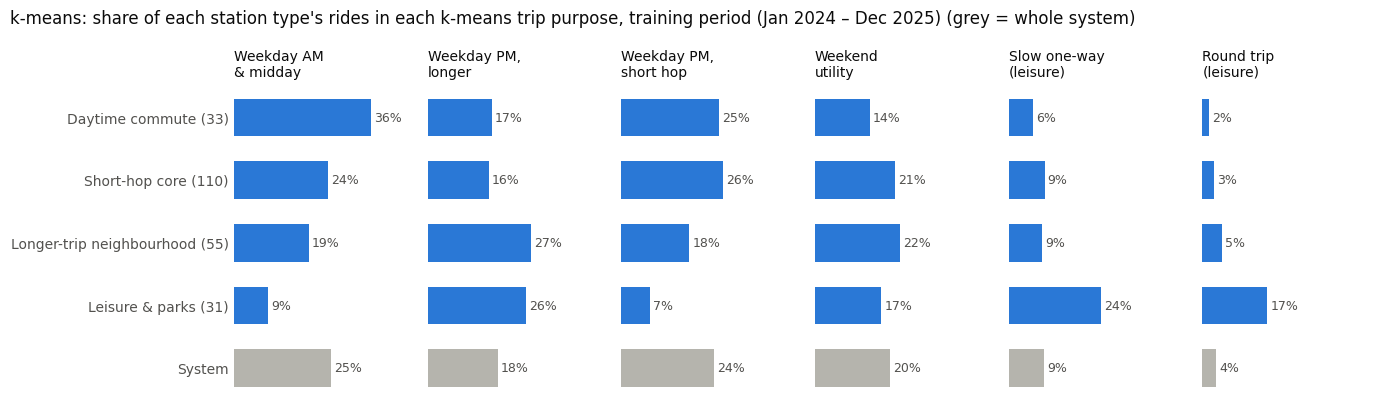

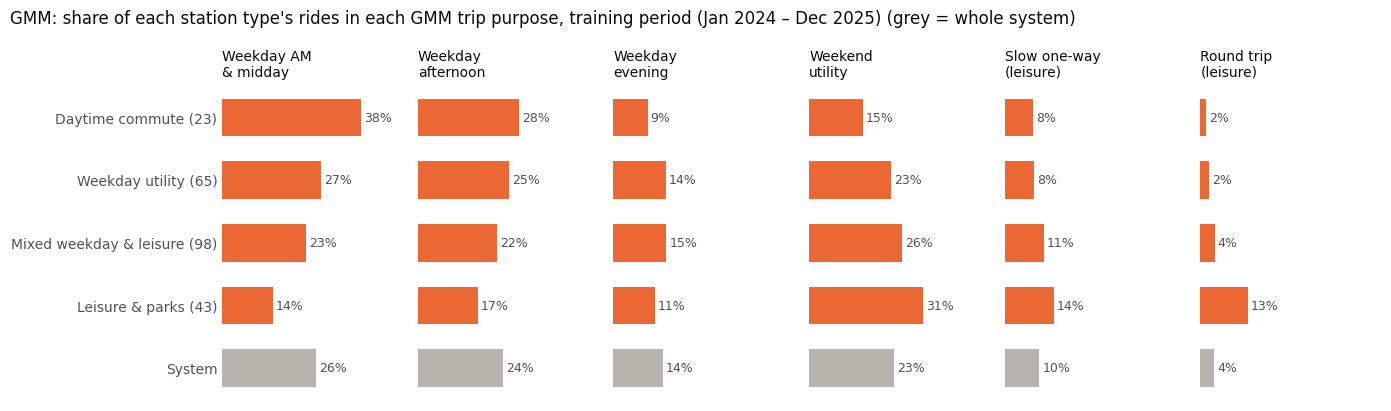

In [83]:
# The ride-mix chart for each pipeline: station types (rows) × trip purposes (panels), grey = whole system
fig = ride_mix_chart(mix_share.loc[MIX_TYPES, PURPOSES], system_mix, stations_train["mix_type"].value_counts(),
                     "k-means: share of each station type's rides in each k-means trip purpose, training period "
                     "(Jan 2024 – Dec 2025) (grey = whole system)", color=BLUE)
plt.show()
fig = ride_mix_chart(gmm_mix_share.loc[GMM_TYPES, GMM_PURPOSES], gmm_system_mix, stations_train["gmm_type"].value_counts(),
                     "GMM: share of each station type's rides in each GMM trip purpose, training period "
                     "(Jan 2024 – Dec 2025) (grey = whole system)", color=ORANGE)
plt.show()

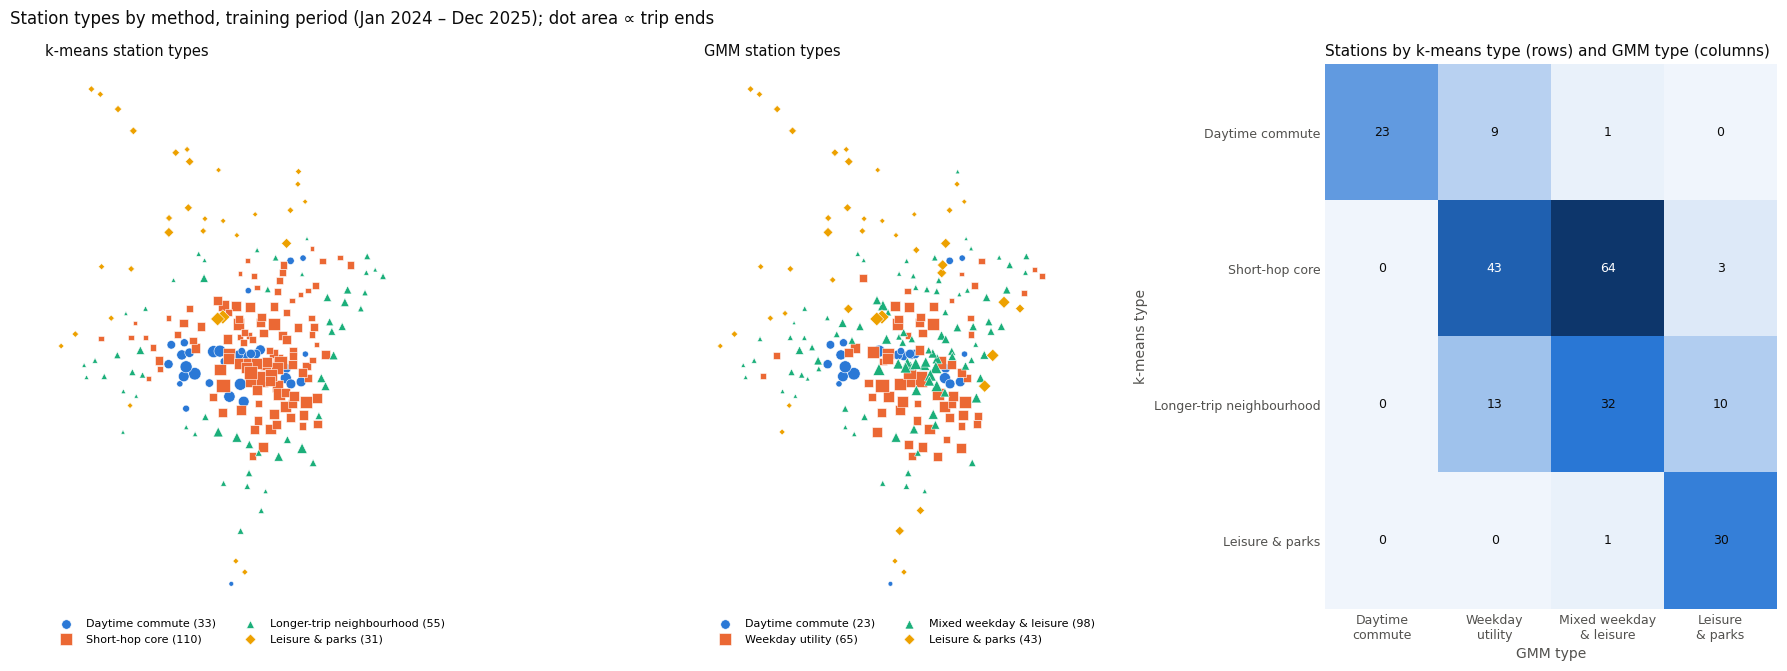

In [84]:
# Where each pipeline's station types are, and how the two typologies line up
fig, axes = plt.subplots(1, 3, figsize=(18, 6.8), gridspec_kw={"width_ratios": [1, 1, 1.05]})
type_map(axes[0], stations_train, "mix_type", MIX_TYPES, "k-means station types")
type_map(axes[1], stations_train, "gmm_type", GMM_TYPES, "GMM station types")
share_heatmap(pd.crosstab(stations_train["mix_type"], stations_train["gmm_type"]).rename_axis(index="k-means type", columns="GMM type"),
              "Stations by k-means type (rows) and GMM type (columns)", fmt="{:.0f}", ax=axes[2])
suptitle(fig, "Station types by method, training period (Jan 2024 – Dec 2025); dot area ∝ trip ends")
fig.tight_layout()
plt.show()

In [87]:
# Trips: k-means vs GMM vs DBSCAN on a shared 8,000-trip sample
ev_trip_rows = np.random.default_rng(7).choice(len(X_trips), 8_000, replace=False)
ev_X = X_trips[ev_trip_rows]
ev_P = PCA(n_components=5).fit(X_trips).transform(ev_X)  # DBSCAN works in 5 PCA components, as in 2.3
ev_eps = float(np.quantile(k_distance(ev_P, 10), 0.90))   # fixed across refits

ev_trip_candidates = [
    Candidate("k-means (k = 6)", lambda rows: KMeans(TRIP_K, n_init=10, random_state=0).fit_predict(ev_X[rows]), ev_X),
    Candidate("GMM (k = 6)", lambda rows: fit_gmm(ev_X[rows], TRIP_K).predict(ev_X[rows]), ev_X),
    Candidate("DBSCAN", lambda rows: DBSCAN(eps=ev_eps, min_samples=10).fit_predict(ev_P[rows]), ev_P),
]
ev_trip_scores = scorecard(ev_trip_candidates,
                           {"casual": trips_train["casual"].to_numpy()[ev_trip_rows], "electric": trips_train["electric"].to_numpy()[ev_trip_rows]},
                           trips_train.iloc[ev_trip_rows][["duration", "dist_km", "speed_kmh", "round_trip", "hour", "weekend"]],
                           reference=trip_km.labels_[ev_trip_rows], n_boot=5)

# Stations: each pipeline end to end on its own features
ev_station_candidates = [
    Candidate("k-means pipeline (k = 4)", lambda rows: KMeans(RIDE_MIX_K, n_init=50, random_state=0).fit_predict(X_ride_mix[rows]), X_ride_mix),
    Candidate("GMM pipeline (k = 4)", lambda rows: fit_gmm(X_gmm_mix[rows], GMM_STATION_K, "diag", n_init=10).predict(X_gmm_mix[rows]), X_gmm_mix),
    Candidate("DBSCAN", lambda rows: DBSCAN(eps=EPS_STATIONS, min_samples=MIN_PTS_STATIONS).fit_predict(X_ride_mix[rows]), X_ride_mix),
]
ev_station_readable = ((stations_train[PURPOSES] * 100).add_prefix("k-means % ")
                       .join((gmm_shares_train[GMM_PURPOSES] * 100).add_prefix("GMM % ")))
ev_station_scores = scorecard(ev_station_candidates,
                              {"AM net flow": stations_train["am_net"].to_numpy(), "casual": stations_train["casual"].to_numpy()},
                              ev_station_readable, reference=stations_train["mix_id"], n_boot=20)
display(sc_show(ev_trip_scores).set_caption("Trips"))
display(sc_show(ev_station_scores).set_caption("Stations (end to end)"))

,clusters,coverage,fit (silhouette),stability,held-out ε²: casual,held-out ε²: electric,interpretability,ARI vs reference
k-means (k = 6),6,100%,0.250,0.95,0.068,0.018,86%,0.94
GMM (k = 6),6,100%,0.208,0.65,0.049,0.034,85%,0.52
DBSCAN,8,96%,0.233,1.00,0.024,0.000,100%,0.27


,clusters,coverage,fit (silhouette),stability,held-out ε²: AM net flow,held-out ε²: casual,interpretability,ARI vs reference
k-means pipeline (k = 4),4,100%,0.282,0.90,0.274,0.317,86%,1.00
GMM pipeline (k = 4),4,100%,0.180,0.70,0.317,0.366,90%,0.30
DBSCAN,1,98%,—,—,—,—,—,—


## <a id="evaluation"></a>Evaluating the clusters: importance, failures, sensitivity, stability

<small>[↑ Contents](#contents)</small>

### Feature importance

In [88]:
# Helpers used only by this analysis
def ablation(X, column_groups: dict, k: int, reference, n_init: int = 10, silhouette_sample=None) -> pd.DataFrame:
    """Drop each feature group in turn, refit k-means, and compare with the full-feature `reference` labels.

    Low ARI means the clusters depend heavily on that group. Silhouette is measured in the reduced feature space.
    """
    X = np.asarray(X)
    silhouette_rows = slice(None) if silhouette_sample is None else silhouette_sample
    rows = []
    for name, dropped_cols in column_groups.items():
        kept = [c for c in range(X.shape[1]) if c not in dropped_cols]
        labels = KMeans(k, n_init=n_init, random_state=0).fit_predict(X[:, kept])
        rows.append({"dropped": name, "ARI vs full": adjusted_rand_score(reference, labels),
                     "silhouette without it": silhouette_score(X[silhouette_rows][:, kept], labels[silhouette_rows])})
    return pd.DataFrame(rows).set_index("dropped")


def permutation_label_change(model, X, column_groups: dict, n_repeats: int = 3, seed: int = 0) -> pd.Series:
    """Share of points whose label (from the frozen `model`) changes when a feature group is shuffled across rows.

    Columns in a group are shuffled together (e.g. hour sine and cosine), so they stay a valid pair.
    """
    X = np.asarray(X)
    rng = np.random.default_rng(seed)
    original = model.predict(X)
    changed = {}
    for name, cols in column_groups.items():
        shares = []
        for _ in range(n_repeats):
            shuffled = X.copy()
            shuffled[:, cols] = X[rng.permutation(len(X))][:, cols]
            shares.append((model.predict(shuffled) != original).mean())
        changed[name] = float(np.mean(shares))
    return pd.Series(changed, name="labels changed when shuffled")


def hbar_panels(table: pd.DataFrame, columns: list, titles: list, formats: list):
    """One horizontal-bar panel per column of `table` (rows = features), sharing the row order."""
    fig, axes = plt.subplots(1, len(columns), figsize=(4.2 * len(columns), 0.45 * len(table) + 1.4), sharey=True,
                             squeeze=False)
    for ax, col, title, fmt in zip(axes[0], columns, titles, formats):
        values = table[col].to_numpy()
        ax.barh(range(len(values)), values, height=0.6, color=BLUE)
        label_values(ax, values, " " + fmt)
        ax.set_title(title, fontsize=10)
        ax.set_xlim(0, max(values.max() * 1.25, 1e-9))
        labelled_bars_axis(ax)
    axes[0, 0].set_yticks(range(len(table)), table.index)
    axes[0, 0].invert_yaxis()
    return fig

,ARI vs full,silhouette without it,labels changed when shuffled
dropped,,,
duration,0.55,0.276,19%
distance,0.61,0.263,17%
speed,0.78,0.289,12%
round trip,0.84,0.240,7%
time of day,0.48,0.370,32%
weekend,0.44,0.257,31%


Silhouette with all features (same sample): 0.244


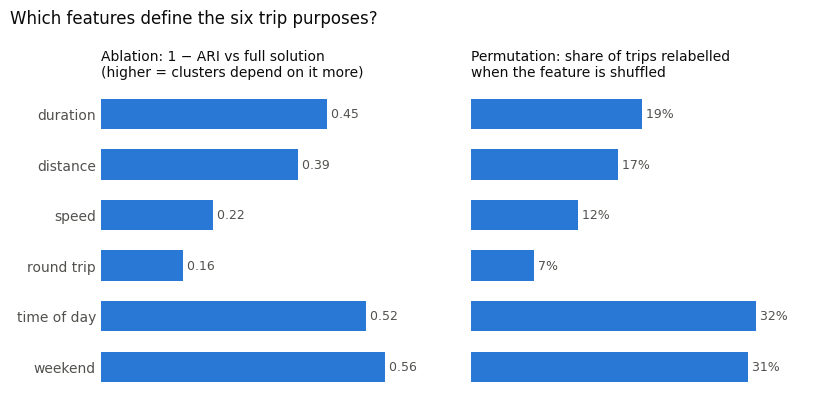

In [89]:
# Trips: ablation (drop a feature group, refit, compare with the original purposes) and permutation
# (shuffle a feature group across trips, relabel with the frozen model, count labels that change)
TRIP_FEATURE_GROUPS = {"duration": [0], "distance": [1], "speed": [2], "round trip": [3], "time of day": [4, 5], "weekend": [6]}
assert [TRIP_FEATURES[i] for cols in TRIP_FEATURE_GROUPS.values() for i in cols] == TRIP_FEATURES

trip_importance = ablation(X_trips, TRIP_FEATURE_GROUPS, TRIP_K, trips_train["purpose_id"],
                           silhouette_sample=silhouette_sample)
trip_importance["labels changed when shuffled"] = permutation_label_change(trip_km, X_trips, TRIP_FEATURE_GROUPS)
full_silhouette = silhouette_score(X_trips[silhouette_sample], trip_km.labels_[silhouette_sample])
display(trip_importance.style.format({"ARI vs full": "{:.2f}", "silhouette without it": "{:.3f}",
                                      "labels changed when shuffled": "{:.0%}"}))
print(f"Silhouette with all features (same sample): {full_silhouette:.3f}")

trip_importance["ablation importance"] = 1 - trip_importance["ARI vs full"]
fig = hbar_panels(trip_importance, ["ablation importance", "labels changed when shuffled"],
                  ["Ablation: 1 − ARI vs full solution\n(higher = clusters depend on it more)",
                   "Permutation: share of trips relabelled\nwhen the feature is shuffled"], ["{:.2f}", "{:.0%}"])
suptitle(fig, "Which features define the six trip purposes?")
fig.tight_layout()
plt.show()

,ARI vs full,silhouette without it,labels changed when shuffled,ablation importance
dropped,,,,
Weekday AM & midday,0.78,0.281,15%,0.22
"Weekday PM, longer",0.51,0.256,20%,0.49
"Weekday PM, short hop",0.86,0.272,16%,0.14
Weekend utility,0.33,0.295,20%,0.67
Slow one-way (leisure),0.86,0.323,6%,0.14
Round trip (leisure),0.94,0.289,6%,0.06


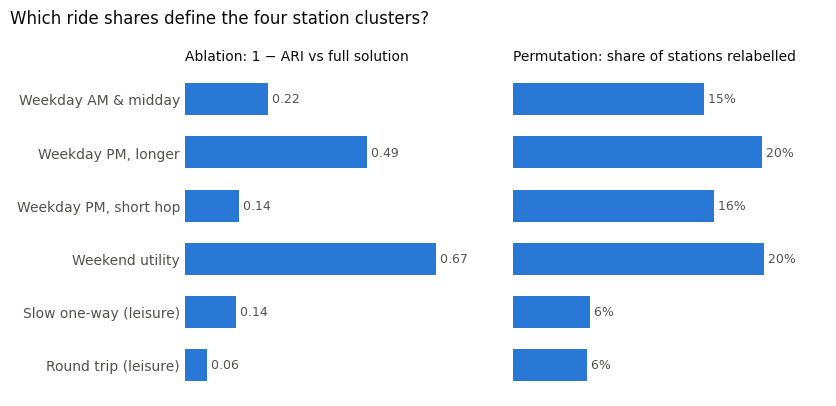

In [90]:
# Stations (ride-mix clusters, k = 4): ablation and permutation over the six purpose shares, then a surrogate tree
STATION_FEATURE_GROUPS = {p: [i] for i, p in enumerate(PURPOSES)}
station_importance = ablation(X_ride_mix, STATION_FEATURE_GROUPS, RIDE_MIX_K, stations_train["mix_id"], n_init=50)
station_importance["labels changed when shuffled"] = permutation_label_change(
    ride_mix_km, X_ride_mix, STATION_FEATURE_GROUPS, n_repeats=20)
station_importance["ablation importance"] = 1 - station_importance["ARI vs full"]
display(station_importance.style.format({"ARI vs full": "{:.2f}", "ablation importance": "{:.2f}",
                                         "silhouette without it": "{:.3f}", "labels changed when shuffled": "{:.0%}"}))
fig = hbar_panels(station_importance, ["ablation importance", "labels changed when shuffled"],
                  ["Ablation: 1 − ARI vs full solution", "Permutation: share of stations relabelled"], ["{:.2f}", "{:.0%}"])
suptitle(fig, "Which ride shares define the four station clusters?")
fig.tight_layout()
plt.show()

### Failure analysis



,median,share_negative,trips
Weekday AM & midday,0.33,1%,"5,015"
"Weekday PM, longer",0.21,6%,"3,545"
"Weekday PM, short hop",0.29,0%,"4,821"
Weekend utility,0.15,2%,"3,955"
Slow one-way (leisure),0.13,20%,"1,872"
Round trip (leisure),0.56,0%,792


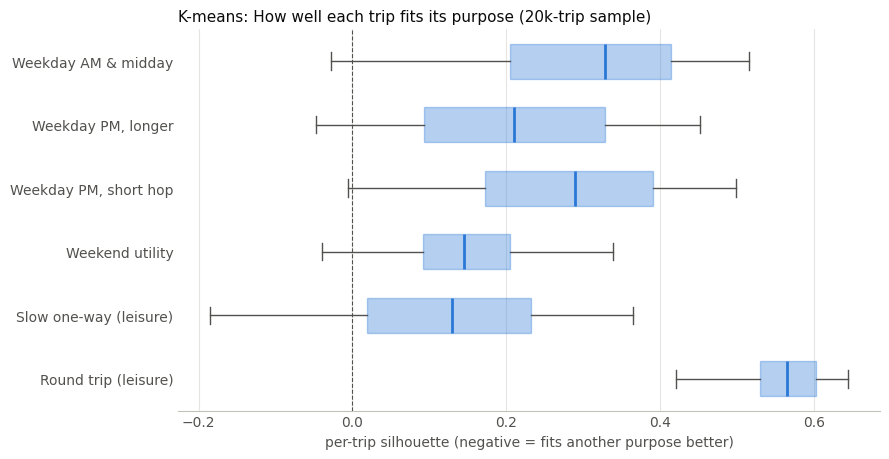

In [91]:
# Trips: per-trip silhouette (on the 20k sample). Negative = closer on average to another purpose than to its own
trip_silhouette = pd.Series(silhouette_samples(X_trips[silhouette_sample], trip_km.labels_[silhouette_sample]))
trip_sample_purpose = pd.Series(trips_train["purpose"].to_numpy()[silhouette_sample])
display(trip_silhouette.groupby(trip_sample_purpose, observed=True)
        .agg(median="median", share_negative=lambda s: (s < 0).mean(), trips="size").loc[PURPOSES]
        .style.format({"median": "{:.2f}", "share_negative": "{:.0%}", "trips": "{:,}"}))
fig, ax = plt.subplots(figsize=(9, 0.55 * len(PURPOSES) + 1.4))
ax.boxplot([trip_silhouette[trip_sample_purpose == p].to_numpy() for p in PURPOSES], orientation="horizontal",
           widths=0.55, showfliers=False, patch_artist=True,
           boxprops={"facecolor": BLUE, "edgecolor": BLUE, "alpha": 0.35}, medianprops={"color": BLUE, "lw": 2},
           whiskerprops={"color": MUTED}, capprops={"color": MUTED})
ax.axvline(0, color=MUTED, lw=0.8, ls="--")
ax.set_yticks(range(1, len(PURPOSES) + 1), PURPOSES)
ax.invert_yaxis()
vertical_gridlines(ax)
ax.set(xlabel="per-trip silhouette (negative = fits another purpose better)",
       title="K-means: How well each trip fits its purpose (20k-trip sample)")
fig.tight_layout()
plt.show()

### Sensitivity analysis

How much do the results depend on arbitrary choices: the random seed, the particular trips and stations in the data, the 200-trip-end minimum, and the AM/PM windows used for net flow?

In [92]:
# Helpers used only by this analysis
def seed_stability(X, k: int, seeds, n_init: int = 10) -> pd.Series:
    """Pairwise ARI between k-means solutions that differ only in random seed."""
    solutions = [KMeans(k, n_init=n_init, random_state=seed).fit_predict(X) for seed in seeds]
    pairwise = [adjusted_rand_score(a, b) for i, a in enumerate(solutions) for b in solutions[i + 1:]]
    return pd.Series(pairwise, name="pairwise ARI across seeds")

In [93]:
# Random seed and resampling: refit on the same data with other seeds, and on bootstrap resamples of the rows
trip_seeds = seed_stability(X_trips, TRIP_K, seeds=range(5))
station_seeds = seed_stability(X_ride_mix, RIDE_MIX_K, seeds=range(20), n_init=50)
trip_bootstrap = resample_stability(X_trips, TRIP_K, trips_train["purpose_id"], sizes=[len(X_trips)], reps=5, replace=True)
station_bootstrap = resample_stability(X_ride_mix, RIDE_MIX_K, stations_train["mix_id"], sizes=[len(X_ride_mix)],
                                       reps=50, n_init=50, replace=True)
stability_summary = pd.DataFrame({
    "trips: other seeds": trip_seeds.describe(), "trips: bootstrap resamples": trip_bootstrap["ARI vs reference"].describe(),
    "stations: other seeds": station_seeds.describe(), "stations: bootstrap resamples": station_bootstrap["ARI vs reference"].describe(),
}).loc[["count", "min", "25%", "50%", "mean"]].T
display(stability_summary.style.format("{:.2f}").format("{:.0f}", subset=["count"]))

,count,min,25%,50%,mean
trips: other seeds,10,0.98,0.98,1.00,0.99
trips: bootstrap resamples,5,0.97,0.97,0.98,0.98
stations: other seeds,190,0.94,0.95,0.99,0.98
stations: bootstrap resamples,50,0.29,0.56,0.84,0.74


In [94]:
# Is station bootstrap instability specific to k = 4? Refit on bootstrap resamples of stations at each k
stability_by_k = []
for k in range(2, 8):
    reference = KMeans(k, n_init=50, random_state=0).fit_predict(X_ride_mix)
    boot = resample_stability(X_ride_mix, k, reference, sizes=[len(X_ride_mix)], reps=50, n_init=50, replace=True)
    stability_by_k.append({"k": k, "median ARI": boot["ARI vs reference"].median(), "10th pct": boot["ARI vs reference"].quantile(0.1)})
display(pd.DataFrame(stability_by_k).set_index("k").round(2))

,median ARI,10th pct
k,,
2,0.83,0.76
3,0.41,0.33
4,0.84,0.46
5,0.81,0.56
6,0.62,0.52
7,0.82,0.60


In [95]:
# The 200-trip-end minimum: rebuild the station table at other minimums, refit the ride-mix clusters,
# and compare with the original assignment on the stations both versions contain
min_ends_rows = []
for min_ends in [100, 150, 200, 300, 400, 600]:
    table = station_table(ends_train, trips_train, stations, min_ends=min_ends)
    X = StandardScaler().fit_transform(table[PURPOSES])
    labels = pd.Series(KMeans(RIDE_MIX_K, n_init=50, random_state=0).fit_predict(X), index=table.index)
    common = table.index.intersection(stations_train.index)
    min_ends_rows.append({"min trip ends": min_ends, "stations": len(table), "silhouette": silhouette_score(X, labels),
                          "ARI vs original (common stations)": adjusted_rand_score(stations_train.loc[common, "mix_id"], labels[common])})
display(pd.DataFrame(min_ends_rows).set_index("min trip ends").round(3))

,stations,silhouette,ARI vs original (common stations)
min trip ends,,,
100,305,0.270,0.951
150,301,0.270,0.923
200,301,0.270,0.923
300,298,0.272,0.937
400,294,0.271,0.937
600,293,0.272,0.937


In [96]:
# The AM/PM flow windows (used by the k = 5 purpose-mix + flow station types): try neighbouring windows.
# The k = 5 types are rebuilt here from the station table, so this check doesn't need section 3's alternative cells.
MIX_FLOW_K = 5
flow_window_reference = KMeans(MIX_FLOW_K, n_init=50, random_state=0).fit_predict(
    StandardScaler().fit_transform(stations_train[PURPOSES + ["am_net", "pm_net"]]))
AM_WINDOWS, PM_WINDOWS = [(6, 9), (7, 9), (6, 10), (7, 10)], [(15, 18), (16, 18), (16, 19), (15, 19)]
window_ari = pd.DataFrame(index=[f"AM {a}–{b}" for a, b in AM_WINDOWS], columns=[f"PM {a}–{b}" for a, b in PM_WINDOWS], dtype=float)
for am in AM_WINDOWS:
    for pm in PM_WINDOWS:
        table = stations_train[PURPOSES].assign(
            am_net=peak_net_flow(ends_train, *am).reindex(stations_train.index).fillna(0),
            pm_net=peak_net_flow(ends_train, *pm).reindex(stations_train.index).fillna(0))
        labels = KMeans(MIX_FLOW_K, n_init=50, random_state=0).fit_predict(StandardScaler().fit_transform(table))
        window_ari.loc[f"AM {am[0]}–{am[1]}", f"PM {pm[0]}–{pm[1]}"] = adjusted_rand_score(flow_window_reference, labels)
display(window_ari.style.format("{:.2f}").set_caption("ARI vs the original k = 5 station types (original windows: AM 6–9, PM 15–18)"))

,PM 15–18,PM 16–18,PM 16–19,PM 15–19
AM 6–9,1.00,0.82,0.82,0.99
AM 7–9,1.00,0.82,0.82,0.99
AM 6–10,0.97,0.82,0.82,0.97
AM 7–10,0.93,0.82,0.82,0.97


## AI Reference list

Generative AI was used as a coding assistance tool and to facilitate rapid experimentation. It was especially helpful with refactoring and standardization.
* Refactoring
* Standardizing charts
* DBscan structure
* Parts of GMM
* Expanding sensitivity analysis
* Geo and mapping features
* Ablation
* Biplot
* Scorecard compilation structure

